# SMS spam classification: experiment and engineering report

This assessment compares 60 local ML configurations across original training data, LLM text augmentation and SMOTE, seven hosted generative LLMs, and seven hosted decision models. The task is to reproduce the supplied SMS Spam Collection labels; no particular MoneyMe blocking workflow is assumed.

The assessment asks for two classifiers: a supervised ML classifier and a generative LLM classifier. I also explored specialized decision models because I was curious about this recent direction in AI and wanted to compare their classification quality, latency and cost with the two required approaches.

To account for class imbalance, I used group-aware stratified splits and cross-validation, selected numeric ML configurations using spam F1, and reported spam precision/recall alongside accuracy. I searched class-weight or positive-class-weight settings where supported and selected score-based decision thresholds on validation data.

The training-data comparison evaluates original fitting data, LLM-generated spam text augmentation, and SMOTE applied to numerical feature vectors as separate treatments. Augmentation and SMOTE operate only on fitting data; validation and test messages remain unchanged. The treatment results and their evaluation limitations are discussed below.

**Spam is positive.** Configurations and thresholds are selected using development data and frozen before their test predictions. The existing test set was already inspected before the treatment experiment, so treatment results are explicitly exploratory, not fresh independent estimates. The separately frozen serving release retains its original selection provenance. This notebook reads saved experiment artifacts and makes **no paid API requests**. Run commands and deployment instructions are in the repository README. Model IDs and prices reflect the recorded execution date, not a permanent catalog guarantee.

In [1]:
import os
from pathlib import Path

# Support execution from either the repository root or notebook directory.
if not Path("artifacts/splits/manifest.json").exists():
    os.chdir("..")
import pandas as pd
from IPython.display import Image, Markdown, display

from moneyme_sms_spam_classifier.common import read_json
from moneyme_sms_spam_classifier.data import load
from moneyme_sms_spam_classifier.reporting import comparison

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 100)
df = load()
train = df[df.split == "train"]


def figure(name):
    path = Path("reports/figures") / (name + ".png")
    if path.exists():
        display(Image(filename=str(path)))
    else:
        display(Markdown("Figure pending: `" + name + "`"))

## Data provenance and integrity

Provenance records where the data came from and what happened to it. The corpus is the historical English-language SMS Spam Collection, credited to Almeida, Gómez Hidalgo, and Yamakami (2011); see the supplied readme and [UCI](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).

We parse each line at its first tab, validate the label and text, and fingerprint the raw file with SHA-256. Exact duplicates are removed. Conservative template groups mask URLs and digits only in sufficiently long messages; casing/whitespace variants are grouped too. Families stay within one partition and CV fold. These rules catch some near duplicates, not every possible paraphrase. Review `artifacts/splits/families.csv`.

The dataset is historical, from multiple sources, and not chronologically sorted. It cannot establish quality on current Australian financial-services traffic. Public pretraining exposure also cannot be excluded.

,value
raw_sha256,7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de056...
seed,42
raw_rows,5574
raw_labels,"{'ham': 4827, 'spam': 747}"
unique_rows,5171
duplicates_removed,403
groups,5138
grouped_rows,61
grouping_rule,casefold/whitespace; long >=8-word messages ma...
split_counts,"{'test': {'ham': 904, 'spam': 130}, 'train': {..."


label,ham,spam
split,,
test,904,130
train,2710,392
validation,904,131


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,2710.0,71.148708,55.505160,2.0,34.0,53.0,93.0,790.0
spam,392.0,137.239796,29.309769,13.0,129.0,148.0,156.0,197.0


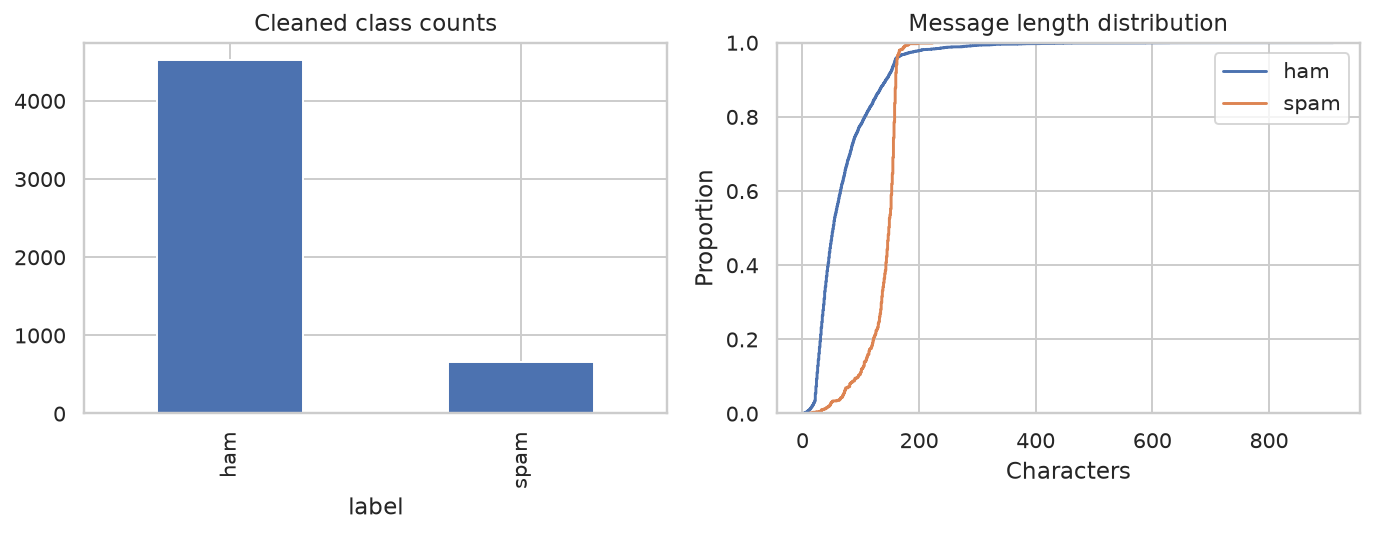

In [2]:
display(pd.Series(read_json("artifacts/splits/manifest.json"), dtype=object).to_frame("value"))
display(pd.crosstab(df.split, df.label))
display(train.groupby("label").text.apply(lambda s: s.str.len().describe()).unstack())
figure("class_and_length")

## Exploratory signals

Length, digit density, capitalization, URLs, and currency mentions are descriptive signals, not hard spam rules. For example, legitimate messages can contain URLs and money. Frequent words/phrases below use training data only. No test messages are used to design model features or prompts.

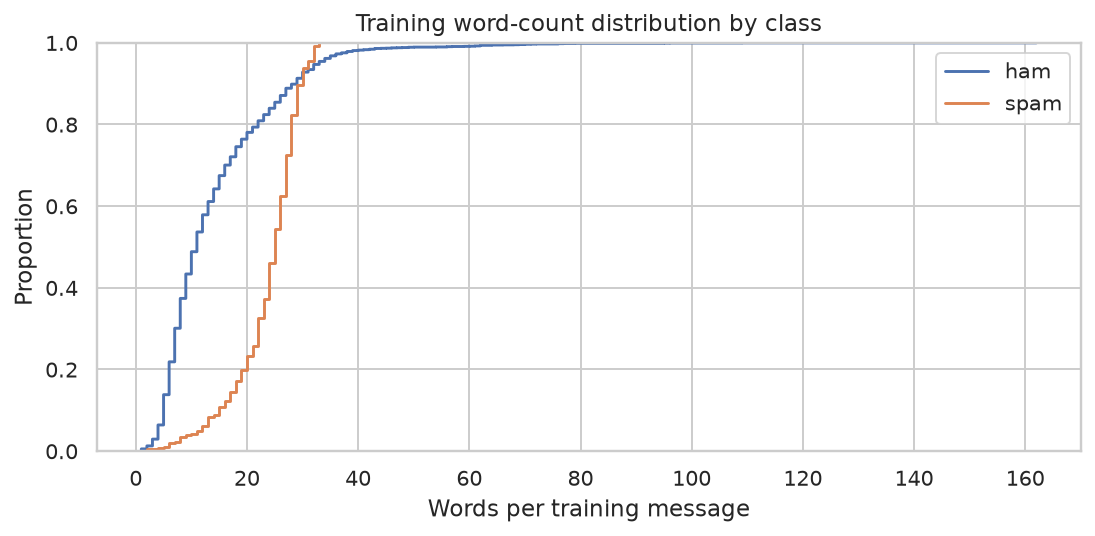

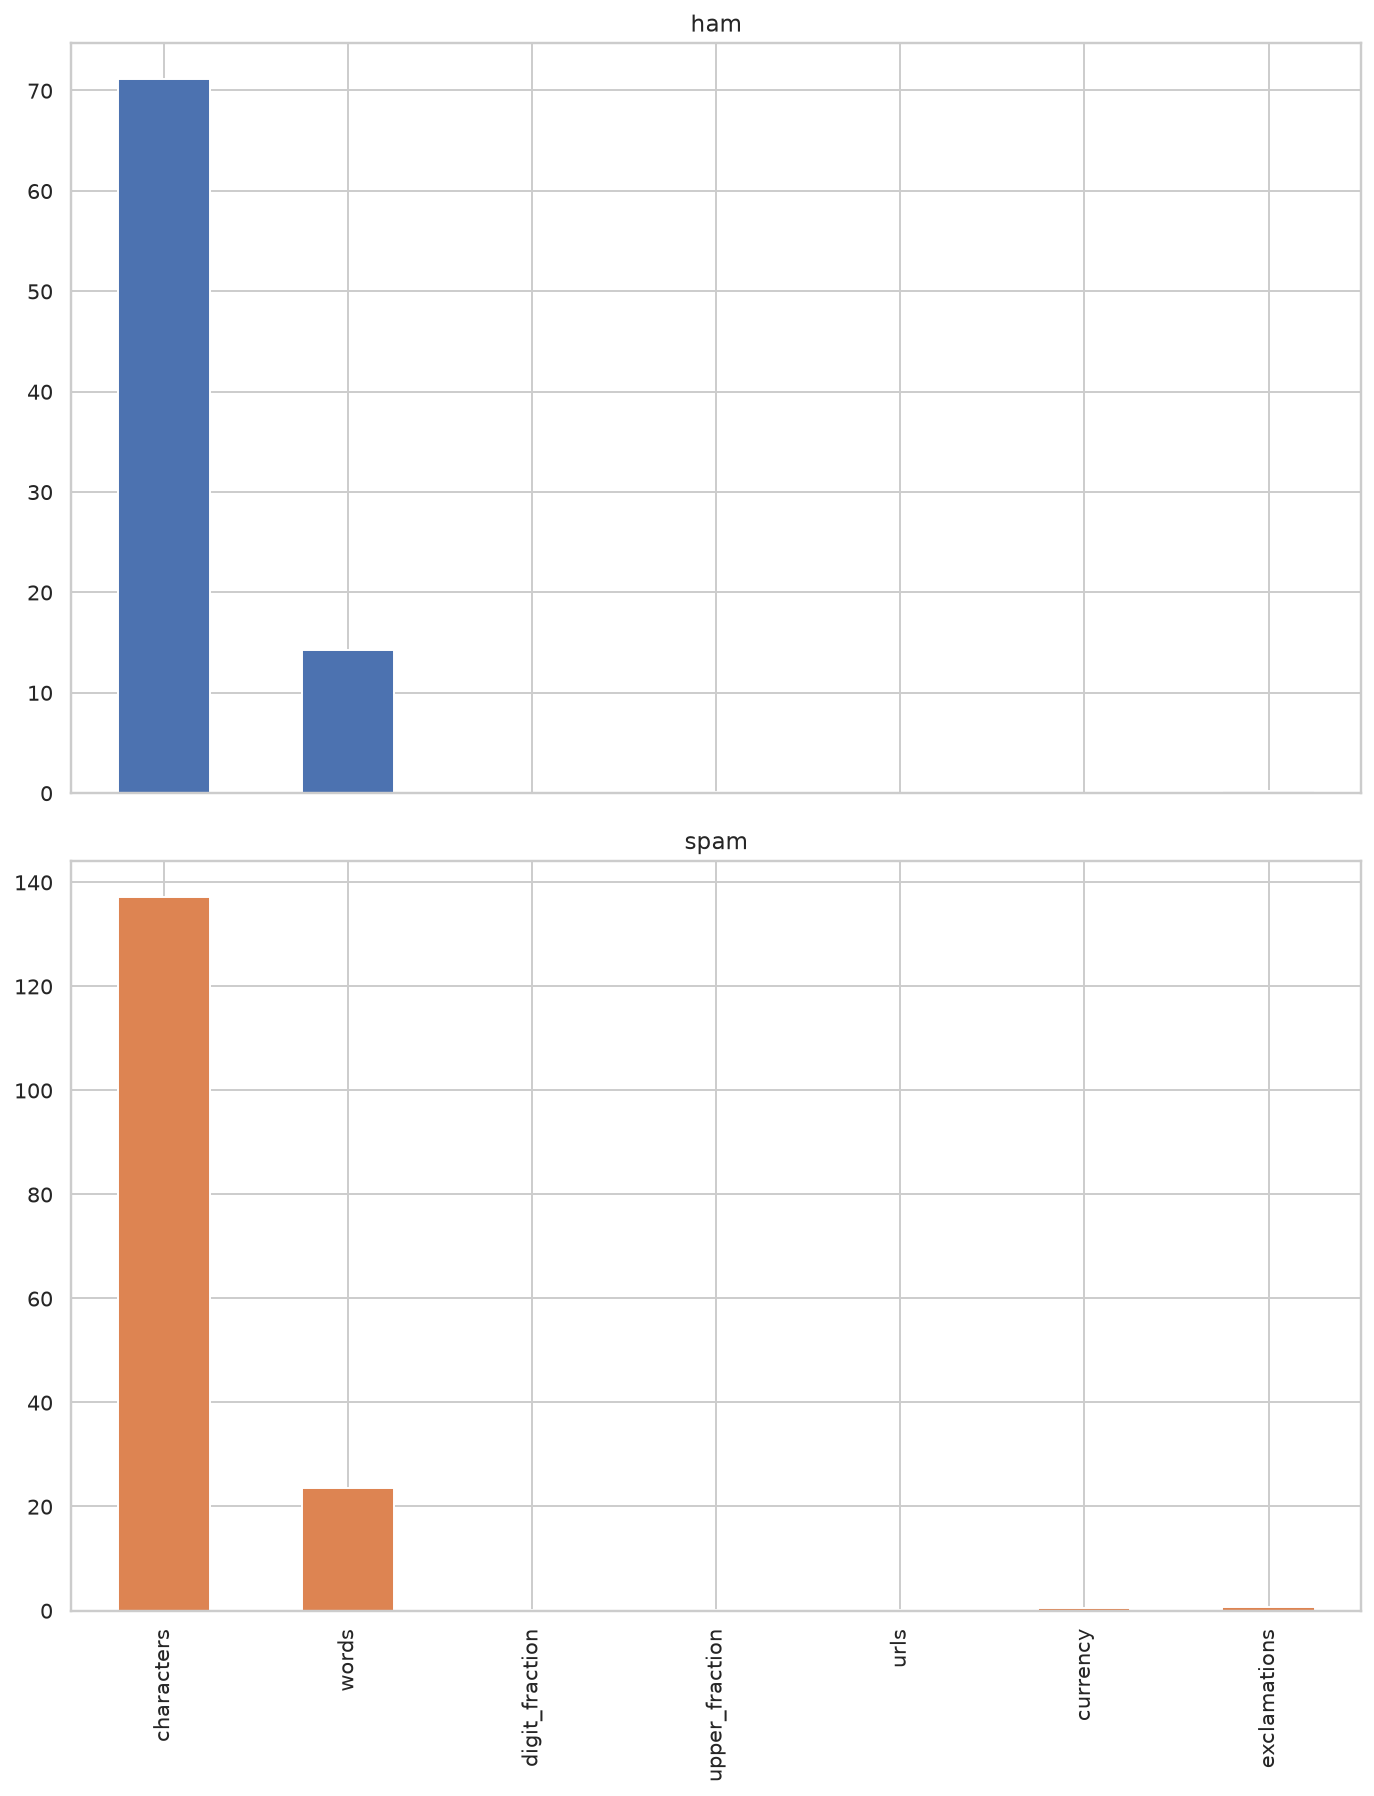

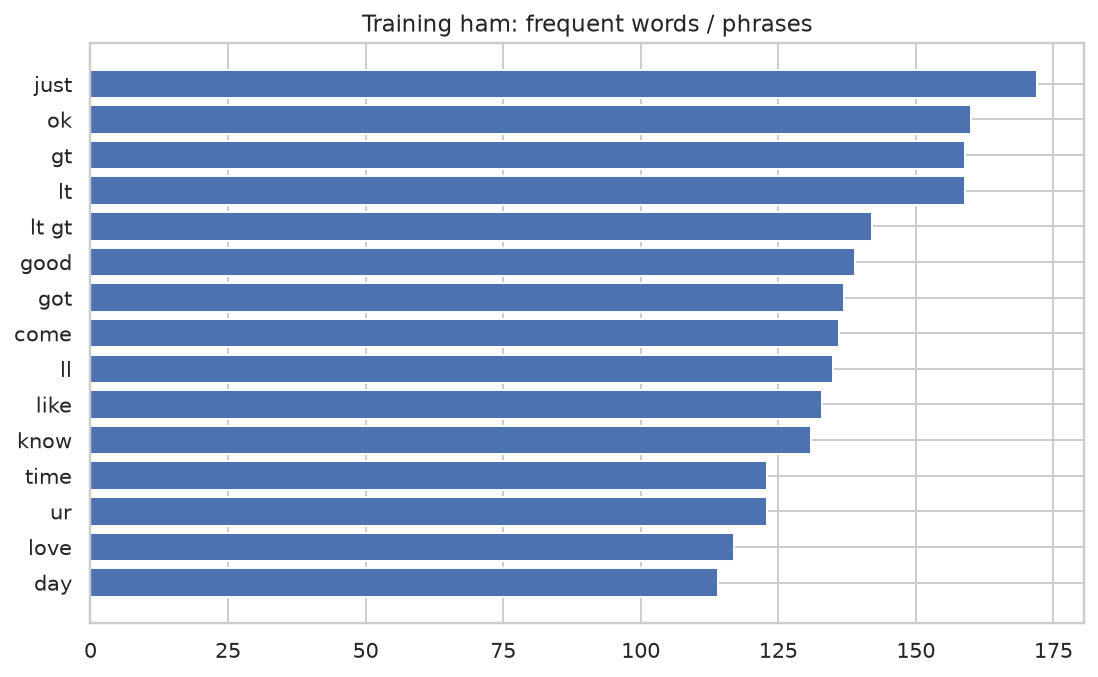

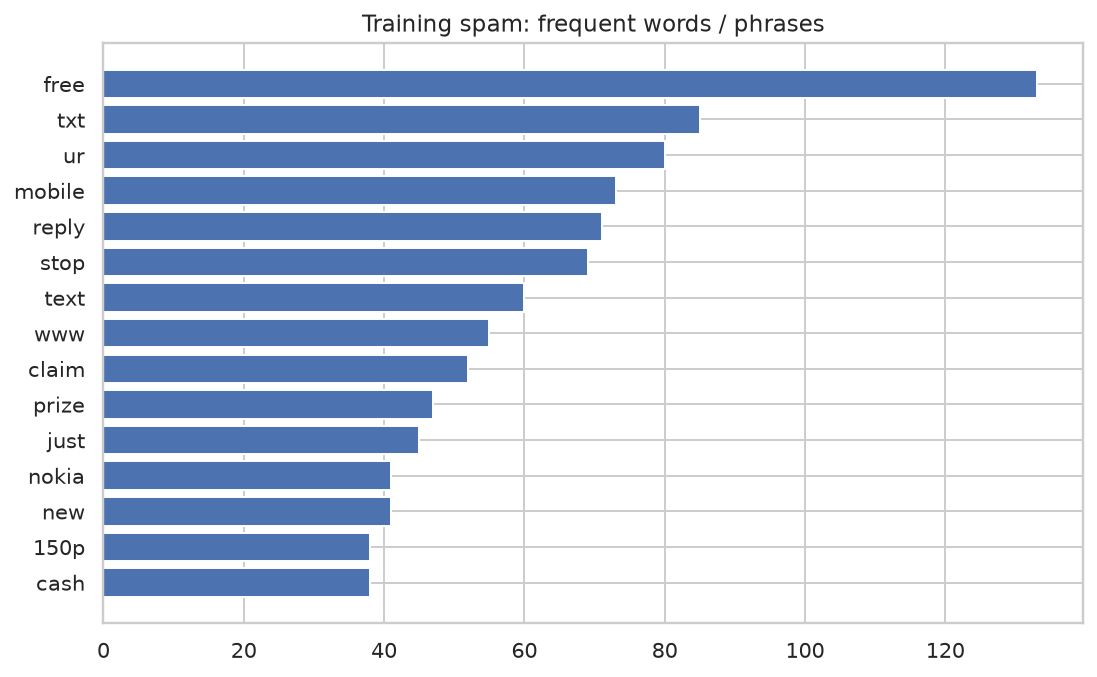

,label,text
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
6,ham,Even my brother is not like to speak with me. ...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [3]:
figure("word_length")
figure("engineered_features")
figure("ngrams_ham")
figure("ngrams_spam")
display(train.groupby("label").head(3)[["label", "text"]])

## Embedding visualization

A frozen sentence encoder maps each message to a contextual vector. PCA/UMAP project **training** vectors into two dimensions, colored by label. Apparent clusters are exploratory: projection changes distances, overlap is expected, and separation is not evidence of test accuracy. Classifiers use full embeddings, not these two plotting coordinates.

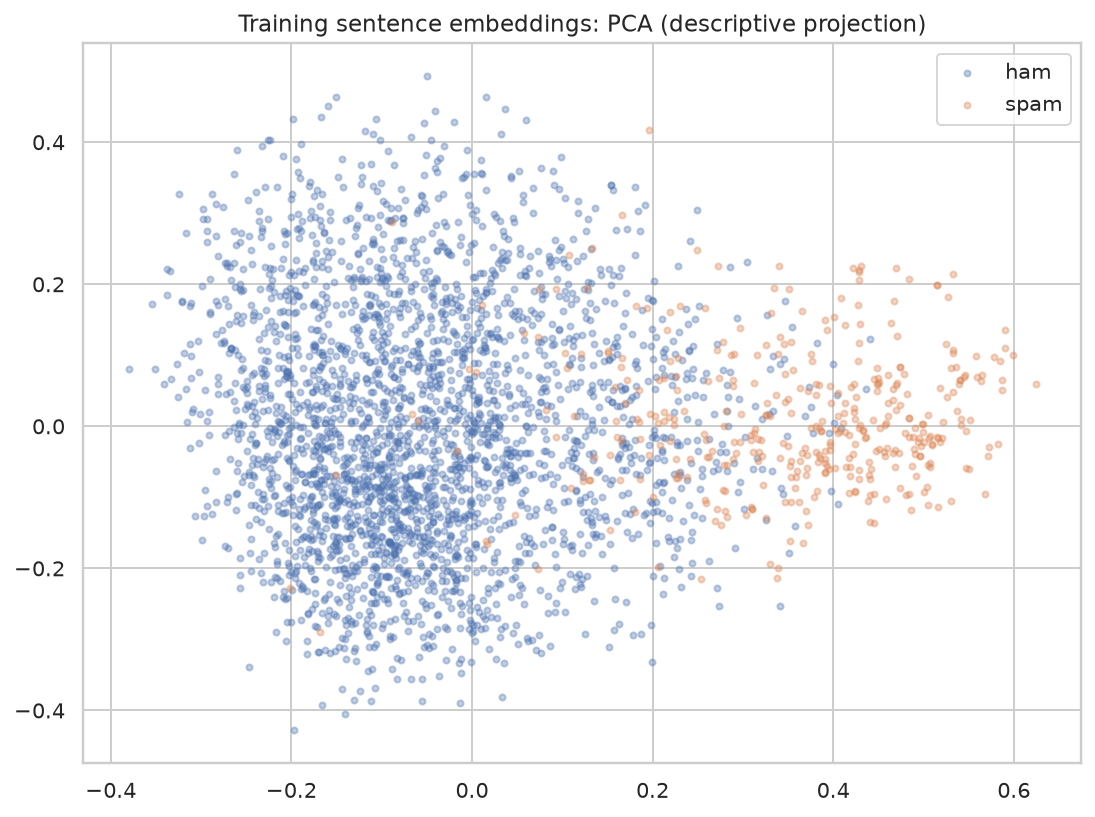

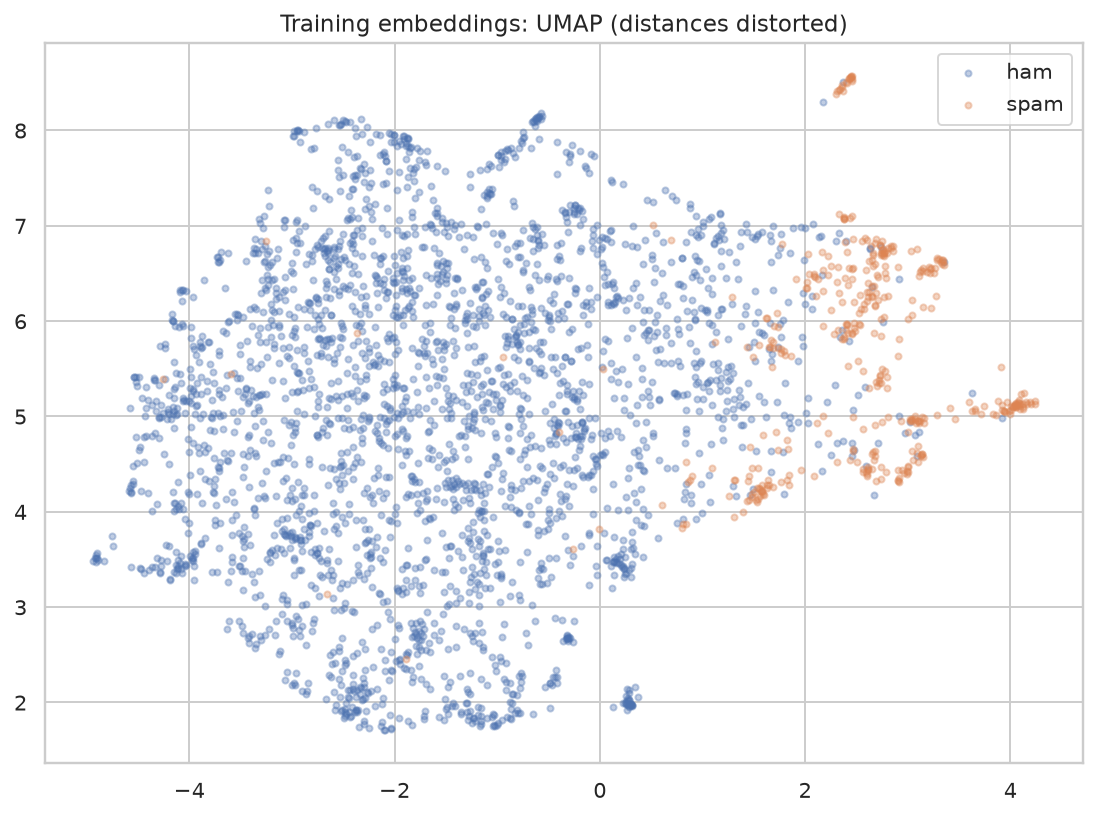

created_at                             2026-11-15T10:32:21.561438+00:00
git_commit                     e0d4d68c755d93eff13d2645e6ccb8d2e9ed71bd
dirty                                                              True
python                                                           3.12.3
platform              Linux-6.18.58.1-microsoft-standard-WSL2-x86_64...
packages              {'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-...
source_hashes         {'src/moneyme_sms_spam_classifier/__init__.py'...
model                            sentence-transformers/all-MiniLM-L6-v2
revision                       1110a243fdf4706b3f48f1d95db1a4f5529b4d41
extraction_seconds                                             4.131157
normalized                                                         True
dimensions                                                          384
max_length                                                          256
dtype: object

In [4]:
figure("embeddings_pca")
figure("embeddings_umap")
if Path("reports/runs/embeddings/manifest.json").exists():
    display(pd.Series(read_json("reports/runs/embeddings/manifest.json"), dtype=object))

## Evaluation and operating policy

The cleaned corpus is split approximately 60/20/20 into train/validation/test, with five fixed group-aware CV folds in training. Vectorizers and fitted transformations learn only within training folds. Class weighting is calculated from training. Validation selects thresholds, prompts, and checkpoints; the test set is used after freezing configurations.

The dummy predicts ham for every message. Its accuracy can be high while spam recall and F1 are zero.

- Precision = TP / (TP + FP): reliability of spam flags.
- Recall = TP / (TP + FN): spam caught.
- F1 = 2TP / (2TP + FP + FN): initial selection metric.
- False positive rate = FP / (FP + TN): legitimate messages incorrectly flagged.
- Accuracy = (TP + TN) / N: useful alongside class-specific measures.

We also explore a 98% precision target on validation with at least 10 positive predictions. This is an illustrative operating point, **not** a MoneyMe requirement or a statistically established guarantee. If unsupported or unattainable, report it. The API classifies; it does not block messages.

Invalid hosted responses count as failures, not ham. Coverage and correct/attempted accuracy accompany successful-response metrics.

## ML methods and tuning

Representation and classifier are separate choices. Compare word counts, word TF-IDF, character TF-IDF, combined word/character features, engineered SMS features, and frozen embeddings. Classifiers include Multinomial NB, Complement NB, Logistic Regression, Linear SVM, Ridge, Random Forest, and XGBoost.

The 54 numeric pipeline/treatment configurations each receive a 20-trial randomized search using the same five training folds and per-pipeline spaces across treatments. The six DistilBERT configurations compare three training settings on original and augmented text. Search histories are beside model artifacts. Threshold optimization is separate from parameter fitting. The historical serving selection has its own search/refinement manifests, separate from this equal-budget comparison.

Frozen embedding models train only the downstream classifier. Head-only DistilBERT freezes its encoder; full fine-tuning updates encoder and head. Head-only training is not LoRA: LoRA learns low-rank internal adapters while original weights remain frozen.

In [5]:
model_root = Path("artifacts/imbalance/models")
if not model_root.exists():
    model_root = Path("artifacts/models")
local = [read_json(p) for p in sorted(model_root.glob("*/result.json"))]
display(
    pd.DataFrame(
        [
            {
                "candidate": r["candidate"],
                "kind": r["kind"],
                "cv_f1": r["cv_f1"],
                "validation_f1": r["validation"]["spam_f1"],
                "precision": r["validation"]["precision"],
                "recall": r["validation"]["recall"],
                "training_s": r["training_seconds"],
                "parameters": r["parameters"],
            }
            for r in local
        ]
    )
)
if Path("reports/runs/encoder/history.json").exists():
    display(pd.DataFrame(read_json("reports/runs/encoder/history.json")))

,candidate,kind,cv_f1,validation_f1,precision,recall,training_s,parameters
0,cnb_word__original,classical,0.918172,0.910569,0.973913,0.854962,5.613387,"{'features__sublinear_tf': True, 'features__ng..."
1,cnb_word__smote,classical,0.912960,0.932806,0.967213,0.900763,8.272139,"{'features__sublinear_tf': False, 'features__n..."
2,cnb_word__text_aug,classical,0.924424,0.935484,0.991453,0.885496,11.315832,"{'features__sublinear_tf': True, 'features__ng..."
3,distilbert_full_2e-05__original,encoder,NaN,0.964706,0.991935,0.938931,158.534542,"{'learning_rate': 2e-05, 'mode': 'full', 'best..."
4,distilbert_full_2e-05__text_aug,encoder,NaN,0.956175,1.000000,0.916031,396.391353,"{'learning_rate': 2e-05, 'mode': 'full', 'best..."
5,distilbert_full_5e-05__original,encoder,NaN,0.957198,0.976190,0.938931,910.263389,"{'learning_rate': 5e-05, 'mode': 'full', 'best..."
6,distilbert_full_5e-05__text_aug,encoder,NaN,0.960938,0.984000,0.938931,1622.944789,"{'learning_rate': 5e-05, 'mode': 'full', 'best..."
7,distilbert_head_0.001__original,encoder,NaN,0.949807,0.960938,0.938931,96.151510,"{'learning_rate': 0.001, 'mode': 'head', 'best..."
8,distilbert_head_0.001__text_aug,encoder,NaN,0.953125,0.976000,0.931298,131.953390,"{'learning_rate': 0.001, 'mode': 'head', 'best..."
9,forest_engineered__original,classical,0.936635,0.922481,0.937008,0.908397,23.518304,"{'classifier__min_samples_leaf': 1, 'classifie..."


,candidate,epoch,metrics
0,distilbert_head_0.001,1,"{'attempted': 1035, 'completed': 1035, 'covera..."
1,distilbert_head_0.001,2,"{'attempted': 1035, 'completed': 1035, 'covera..."
2,distilbert_head_0.001,3,"{'attempted': 1035, 'completed': 1035, 'covera..."
3,distilbert_full_2e-05,1,"{'attempted': 1035, 'completed': 1035, 'covera..."
4,distilbert_full_2e-05,2,"{'attempted': 1035, 'completed': 1035, 'covera..."
5,distilbert_full_2e-05,3,"{'attempted': 1035, 'completed': 1035, 'covera..."
6,distilbert_full_5e-05,1,"{'attempted': 1035, 'completed': 1035, 'covera..."
7,distilbert_full_5e-05,2,"{'attempted': 1035, 'completed': 1035, 'covera..."
8,distilbert_full_5e-05,3,"{'attempted': 1035, 'completed': 1035, 'covera..."


## Training treatments and fold boundaries

The matrix contains 16 classical pipelines and two frozen MiniLM pipelines × three treatments, plus three DistilBERT settings × two treatments = 60 configurations. The always-ham baseline is separate.

`original` uses real fitting messages only. `text_aug` uses Luna-generated, label-preserving variants of fitting-fold spam parents before feature extraction. `smote` interpolates fitting-fold numerical vectors after feature extraction. These are separate arms; ordinary SMOTE does not apply to DistilBERT token sequences.

The final fitting target is 2,710 ham and 2,710 spam; augmentation requires 2,318 accepted additions. Each CV fitting partition has its own target. Generated descendants inherit parent family IDs and cannot enter fitting when their parent family is held out. The original held-out folds, validation and test are never resampled. Class weights are searched explicitly; balanced weighting recomputes from effective fitting counts.

Generated labels are inherited, not independently verified. Integrity filters and assistant qualitative pilot review do not rule out semantic drift, ambiguous source labels, repetitive text or generator-style shortcuts. Cost and parent/configuration provenance are persisted.

The head-only and 0.00002 encoder settings use CUDA/float16 autocast. The 0.00005 setting uses isolated CPU-only PyTorch/float32 with dynamic padding and seeded length-grouped batches for **both** treatments. Backend, precision and batching are matched within each setting, but differ across settings; this is not a controlled learning-rate-only ablation. Per-model manifests record actual execution. Full details: `docs/ml_experiments.md`.

{'requests': 472,
 'accepted': 2550,
 'rejected': 124,
 'covered_parents': 382,
 'pool_sha256': '569f43ba3c4ea7a1f2f373d87ec9b031a8cc0cc67c0935d686ff59d4a370a4cc',
 'accounted_total_usd': 5.274930442014,
 'configuration_id': '5a9c199b94595bb361a7c0c116d528d0bd24956a5c04b67614731798a85a2628'}

{'reviewer': 'assistant qualitative review; not independent human annotation',
 'parents_reviewed': 12,
 'variants_reviewed': 24,
 'selection': 'first two accepted variants per pilot parent',
 'observations': ['Sampled variants broadly preserve source solicitation, action, price and contact details.',
  'Conversational product-trial source has an ambiguous original label; augmentation preserves supplied intent rather than resolving its label.',
  'Malformed URL-only source offers limited lexical diversity.'],
 'decision': 'Proceed with the frozen prompt, automated integrity filters and documented label-noise limitation.',
 'pilot_accepted': 67,
 'pilot_requests': 12}

{'original_spam': 392,
 'accepted_pool': 2550,
 'selected_full_training': 2318,
 'pool_parent_coverage': 382,
 'selected_parent_coverage': 382,
 'maximum_selected_variants_per_parent': 9,
 'rejection_reasons': {'new_contact_or_number': 115, 'duplicate': 9},
 'scope': 'Integrity and distribution diagnostics only; inherited labels are not independently verified.'}

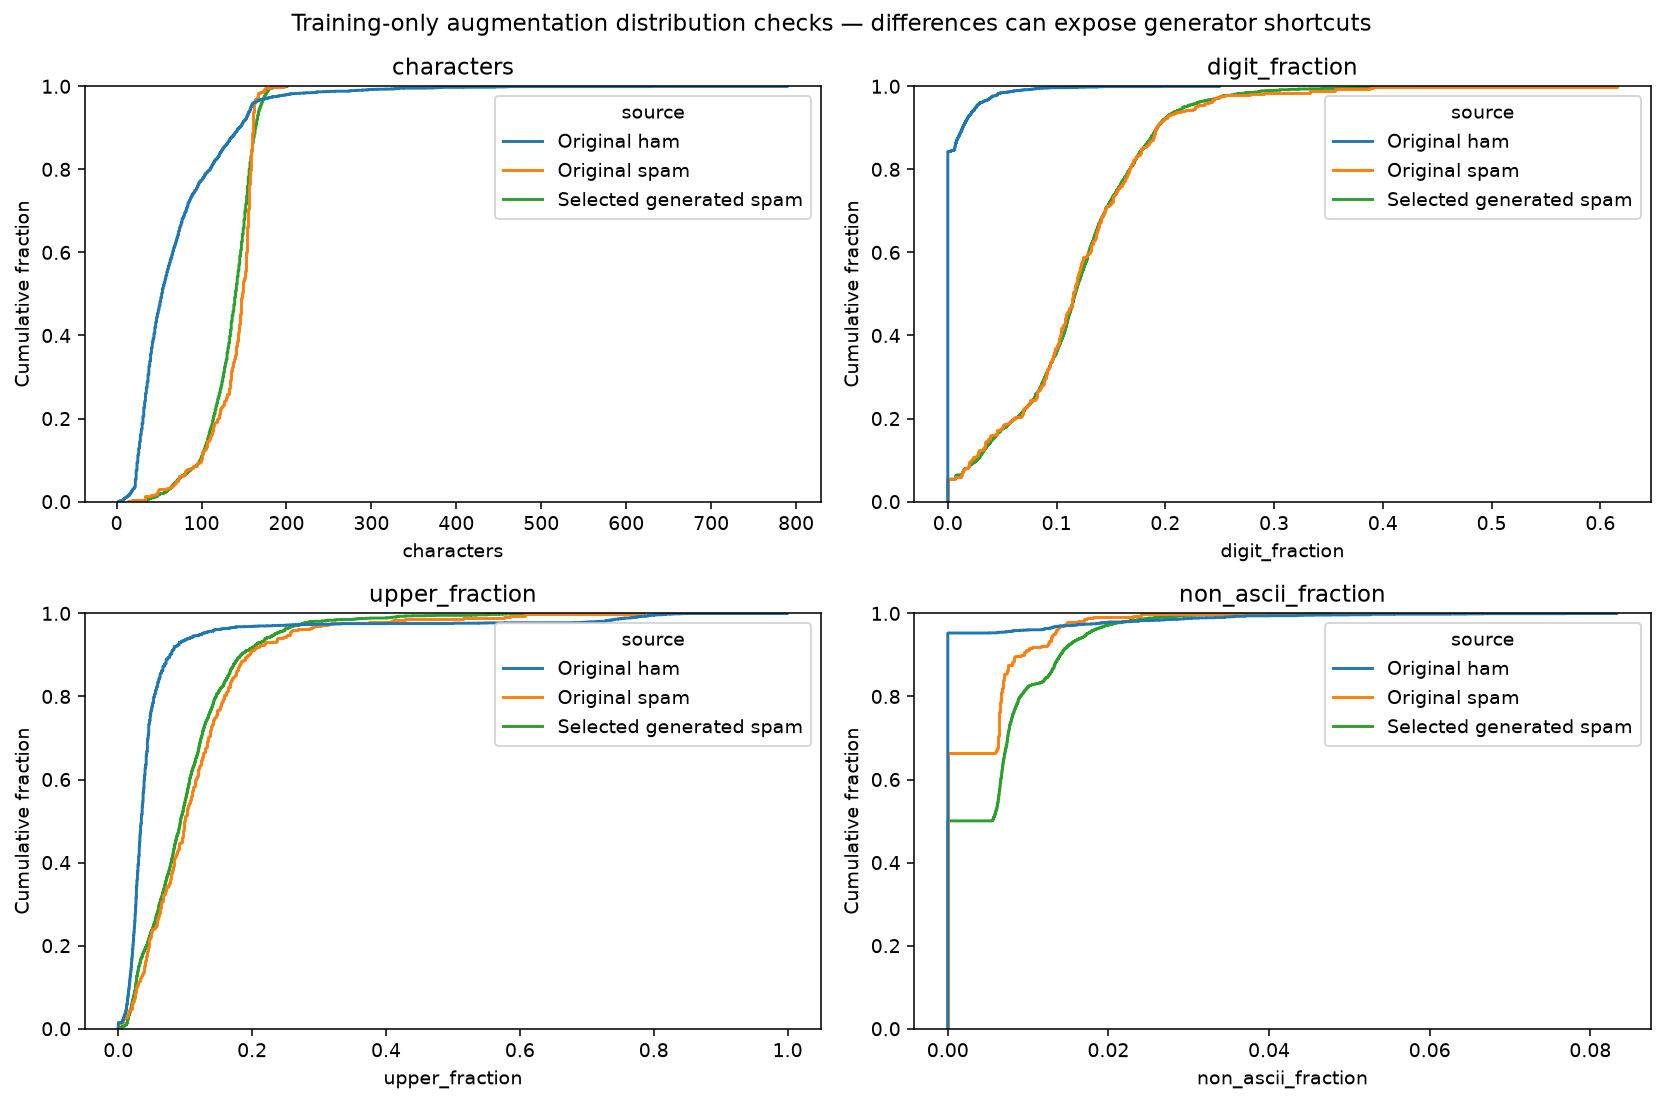

,original_rows,fitted_rows,class_counts
full,3102,5420,"{'0': 2710, '1': 2710}"
fold_0,2481,4336,"{'0': 2168, '1': 2168}"
fold_1,2482,4336,"{'0': 2168, '1': 2168}"
fold_2,2482,4336,"{'0': 2168, '1': 2168}"
fold_3,2482,4336,"{'0': 2168, '1': 2168}"
fold_4,2481,4336,"{'0': 2168, '1': 2168}"


{'numeric_configurations': 54,
 'base_pipelines': 18,
 'trials_per_configuration': 20,
 'folds': 5,
 'finite_cv_score_entries': 5400,
 'identical_sampled_settings_across_treatments': True}

,setting,treatment,device,precision,dynamic_padding,length_grouped_batches
0,distilbert_full_2e-05,original,cuda,autocast_float16,False,False
1,distilbert_full_2e-05,text_aug,cuda,autocast_float16,False,False
2,distilbert_full_5e-05,original,cpu,float32,True,True
3,distilbert_full_5e-05,text_aug,cpu,float32,True,True
4,distilbert_head_0.001,original,cuda,autocast_float16,False,False
5,distilbert_head_0.001,text_aug,cuda,autocast_float16,False,False


Encoder history: original

,candidate,epoch,metrics,device,precision
0,distilbert_head_0.001__original,1,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
1,distilbert_head_0.001__original,2,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
2,distilbert_head_0.001__original,3,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
3,distilbert_full_2e-05__original,1,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
4,distilbert_full_2e-05__original,2,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
5,distilbert_full_2e-05__original,3,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
6,distilbert_full_5e-05__original,1,"{'attempted': 1035, 'completed': 1035, 'covera...",cpu,float32
7,distilbert_full_5e-05__original,2,"{'attempted': 1035, 'completed': 1035, 'covera...",cpu,float32
8,distilbert_full_5e-05__original,3,"{'attempted': 1035, 'completed': 1035, 'covera...",cpu,float32


Encoder history: text_aug

,candidate,epoch,metrics,device,precision
0,distilbert_head_0.001__text_aug,1,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
1,distilbert_head_0.001__text_aug,2,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
2,distilbert_head_0.001__text_aug,3,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
3,distilbert_full_2e-05__text_aug,1,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
4,distilbert_full_2e-05__text_aug,2,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
5,distilbert_full_2e-05__text_aug,3,"{'attempted': 1035, 'completed': 1035, 'covera...",NaN,NaN
6,distilbert_full_5e-05__text_aug,1,"{'attempted': 1035, 'completed': 1035, 'covera...",cpu,float32
7,distilbert_full_5e-05__text_aug,2,"{'attempted': 1035, 'completed': 1035, 'covera...",cpu,float32
8,distilbert_full_5e-05__text_aug,3,"{'attempted': 1035, 'completed': 1035, 'covera...",cpu,float32


,stage,candidate,base_candidate,treatment,attempted,completed,coverage,end_to_end_accuracy,accuracy,spam_f1,macro_f1,precision,...,average_precision,brier,log_loss,cv_f1,training_seconds,training_device,training_precision,evaluation_scope,f1_ci_low,f1_ci_high,bootstrap_repetitions,unit
0,validation,cnb_word__original,cnb_word,original,1035,1035,1.0,0.978744,0.978744,0.910569,0.949254,0.973913,...,0.954944,0.249961,0.693068,0.918172,5.613387,cpu,NaN,Development selection,NaN,NaN,NaN,NaN
1,validation,cnb_word__smote,cnb_word,smote,1035,1035,1.0,0.983575,0.983575,0.932806,0.961725,0.967213,...,0.966264,0.019525,0.081497,0.912960,8.272139,cpu,NaN,Development selection,NaN,NaN,NaN,NaN
2,validation,cnb_word__text_aug,cnb_word,text_aug,1035,1035,1.0,0.984541,0.984541,0.935484,0.963351,0.991453,...,0.966291,0.017620,0.073857,0.924424,11.315832,cpu,NaN,Development selection,NaN,NaN,NaN,NaN
3,validation,distilbert_full_2e-05__original,distilbert_full_2e-05,original,1035,1035,1.0,0.991304,0.991304,0.964706,0.979874,0.991935,...,0.991407,0.012363,0.058470,NaN,158.534542,cuda,autocast_float16,Development selection,NaN,NaN,NaN,NaN
4,validation,distilbert_full_2e-05__text_aug,distilbert_full_2e-05,text_aug,1035,1035,1.0,0.989372,0.989372,0.956175,0.975064,1.000000,...,0.988600,0.013200,0.100770,NaN,396.391353,cuda,autocast_float16,Development selection,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,test,xgboost_engineered__smote,xgboost_engineered,smote,1034,1034,1.0,0.975822,0.975822,0.901186,0.943706,0.926829,...,0.944259,0.024246,0.095045,NaN,24.453344,cpu,NaN,"Exploratory comparison on an existing, previou...",0.863936,0.935864,500.0,template family
116,test,xgboost_engineered__text_aug,xgboost_engineered,text_aug,1034,1034,1.0,0.975822,0.975822,0.901961,0.944086,0.920000,...,0.949217,0.026517,0.108691,NaN,14.556397,cpu,NaN,"Exploratory comparison on an existing, previou...",0.862318,0.934708,500.0,template family
117,test,xgboost_word__original,xgboost_word,original,1034,1034,1.0,0.970986,0.970986,0.873950,0.928778,0.962963,...,0.939998,0.022192,0.089275,NaN,119.575466,cpu,NaN,"Exploratory comparison on an existing, previou...",0.827392,0.920657,500.0,template family
118,test,xgboost_word__smote,xgboost_word,smote,1034,1034,1.0,0.970986,0.970986,0.876033,0.929802,0.946429,...,0.928615,0.026772,0.106405,NaN,525.370447,cpu,NaN,"Exploratory comparison on an existing, previou...",0.831070,0.920138,500.0,template family


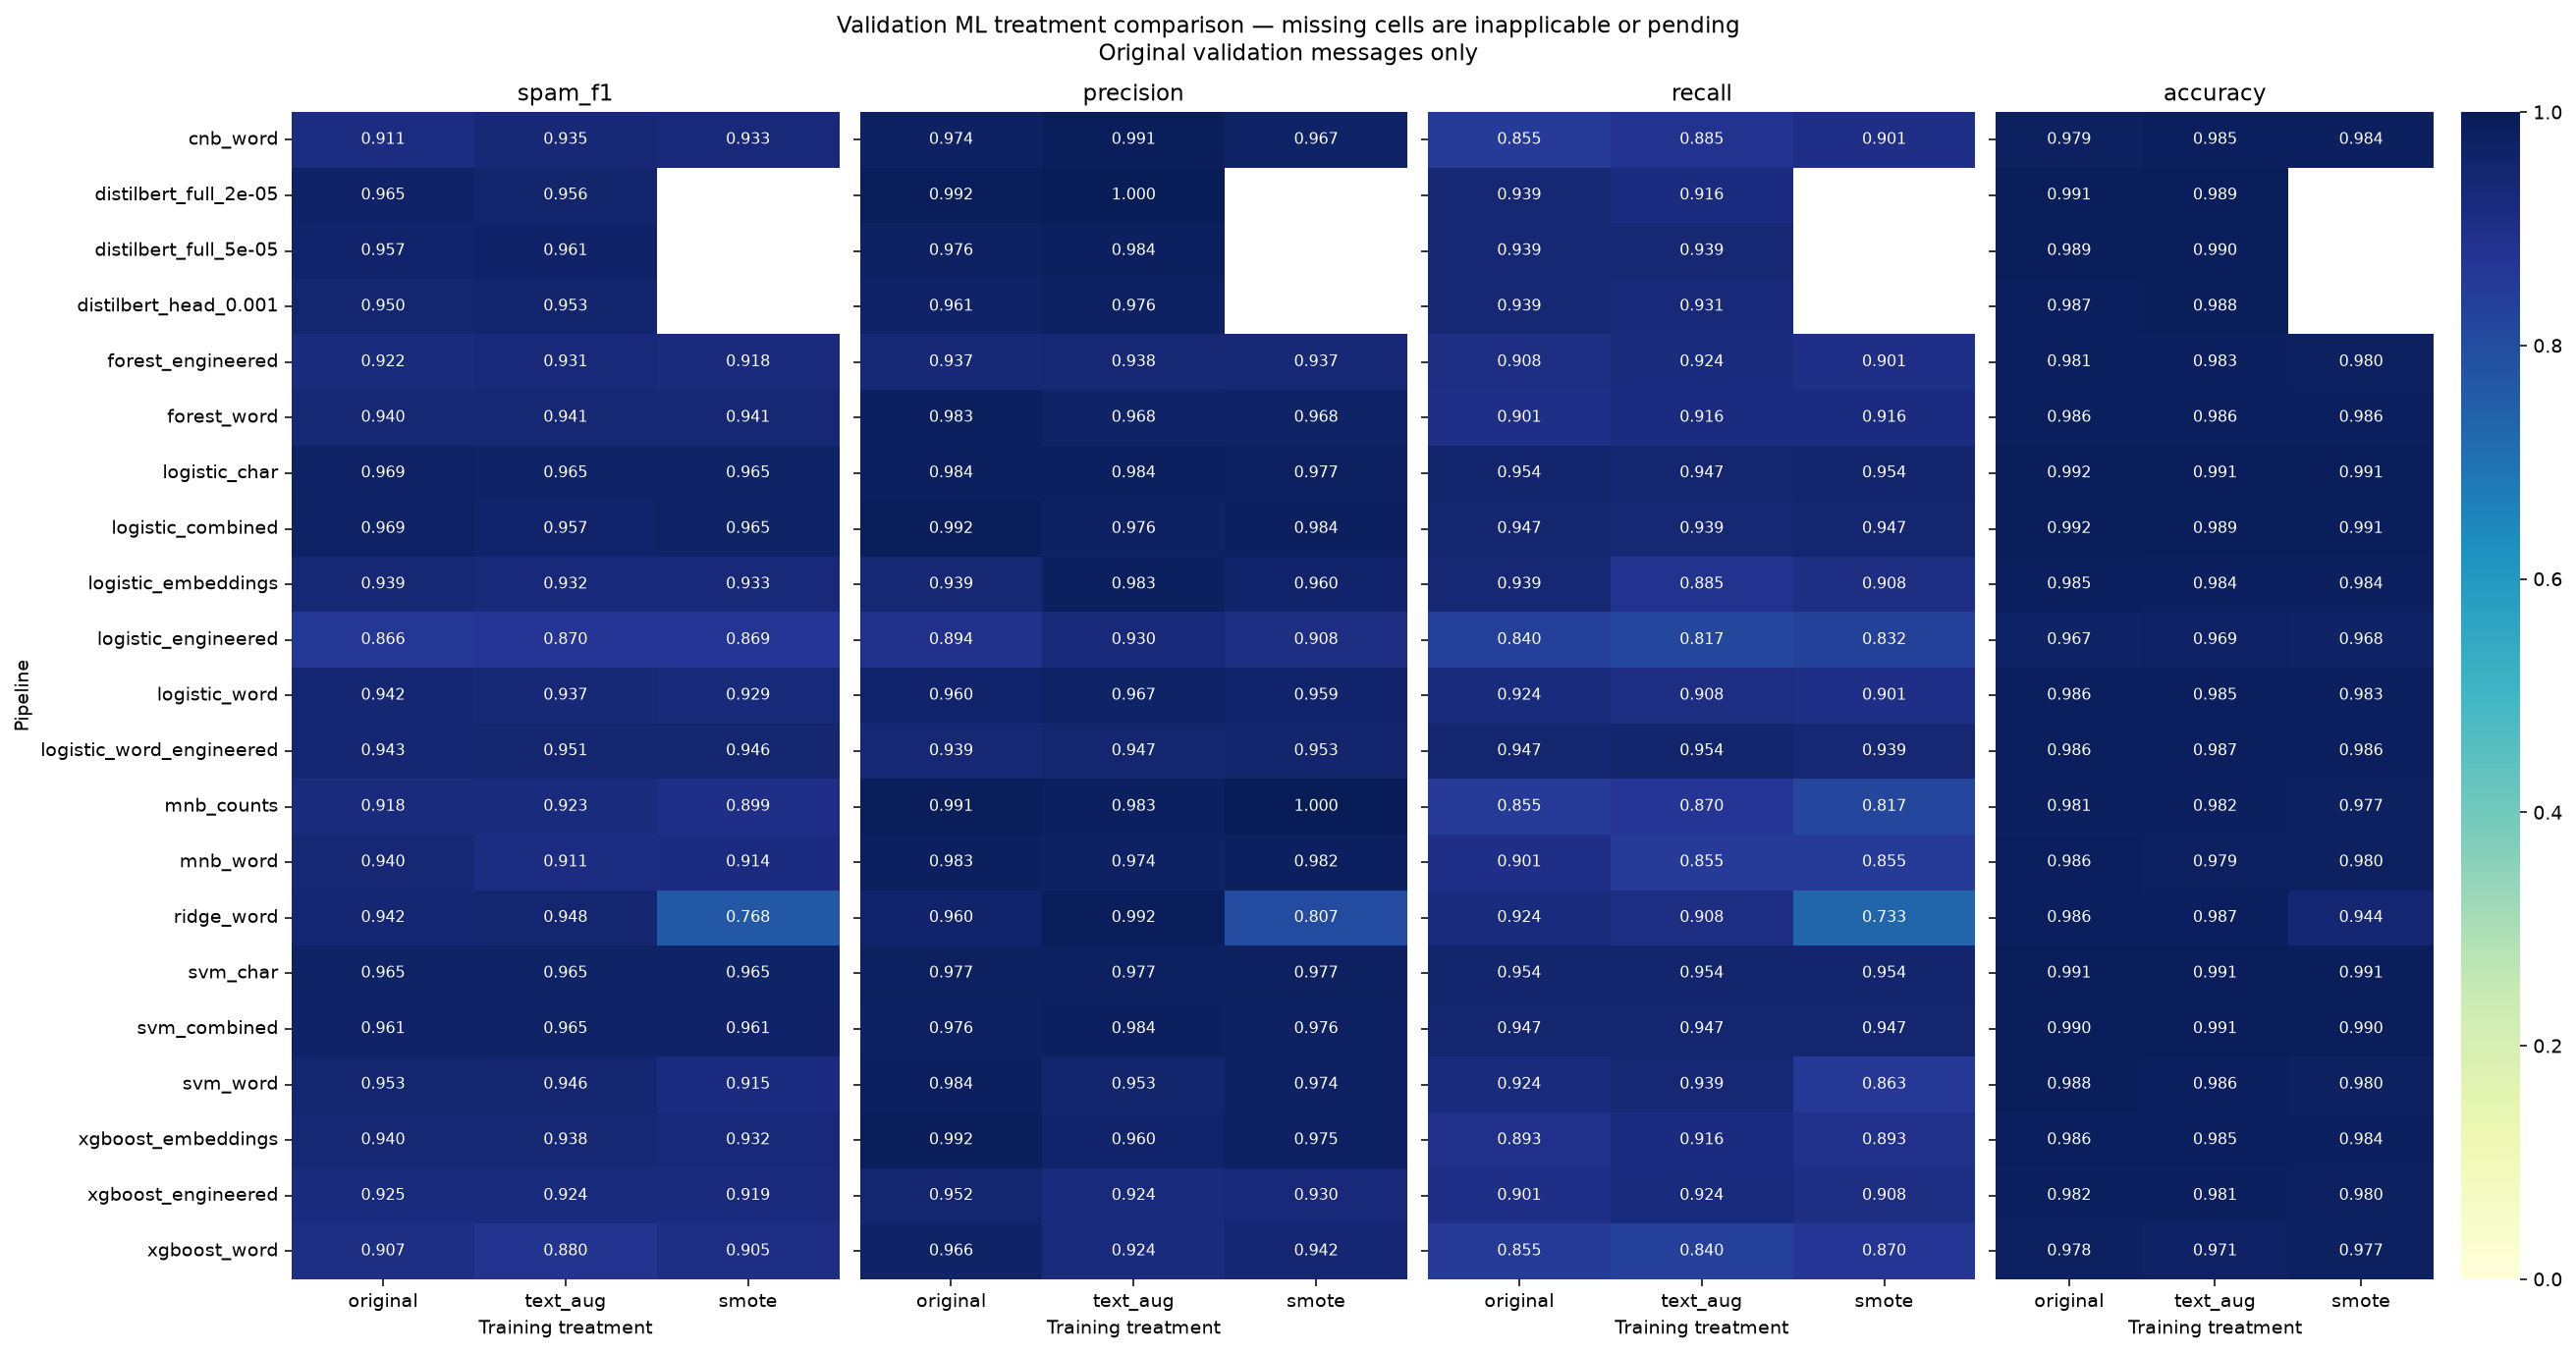

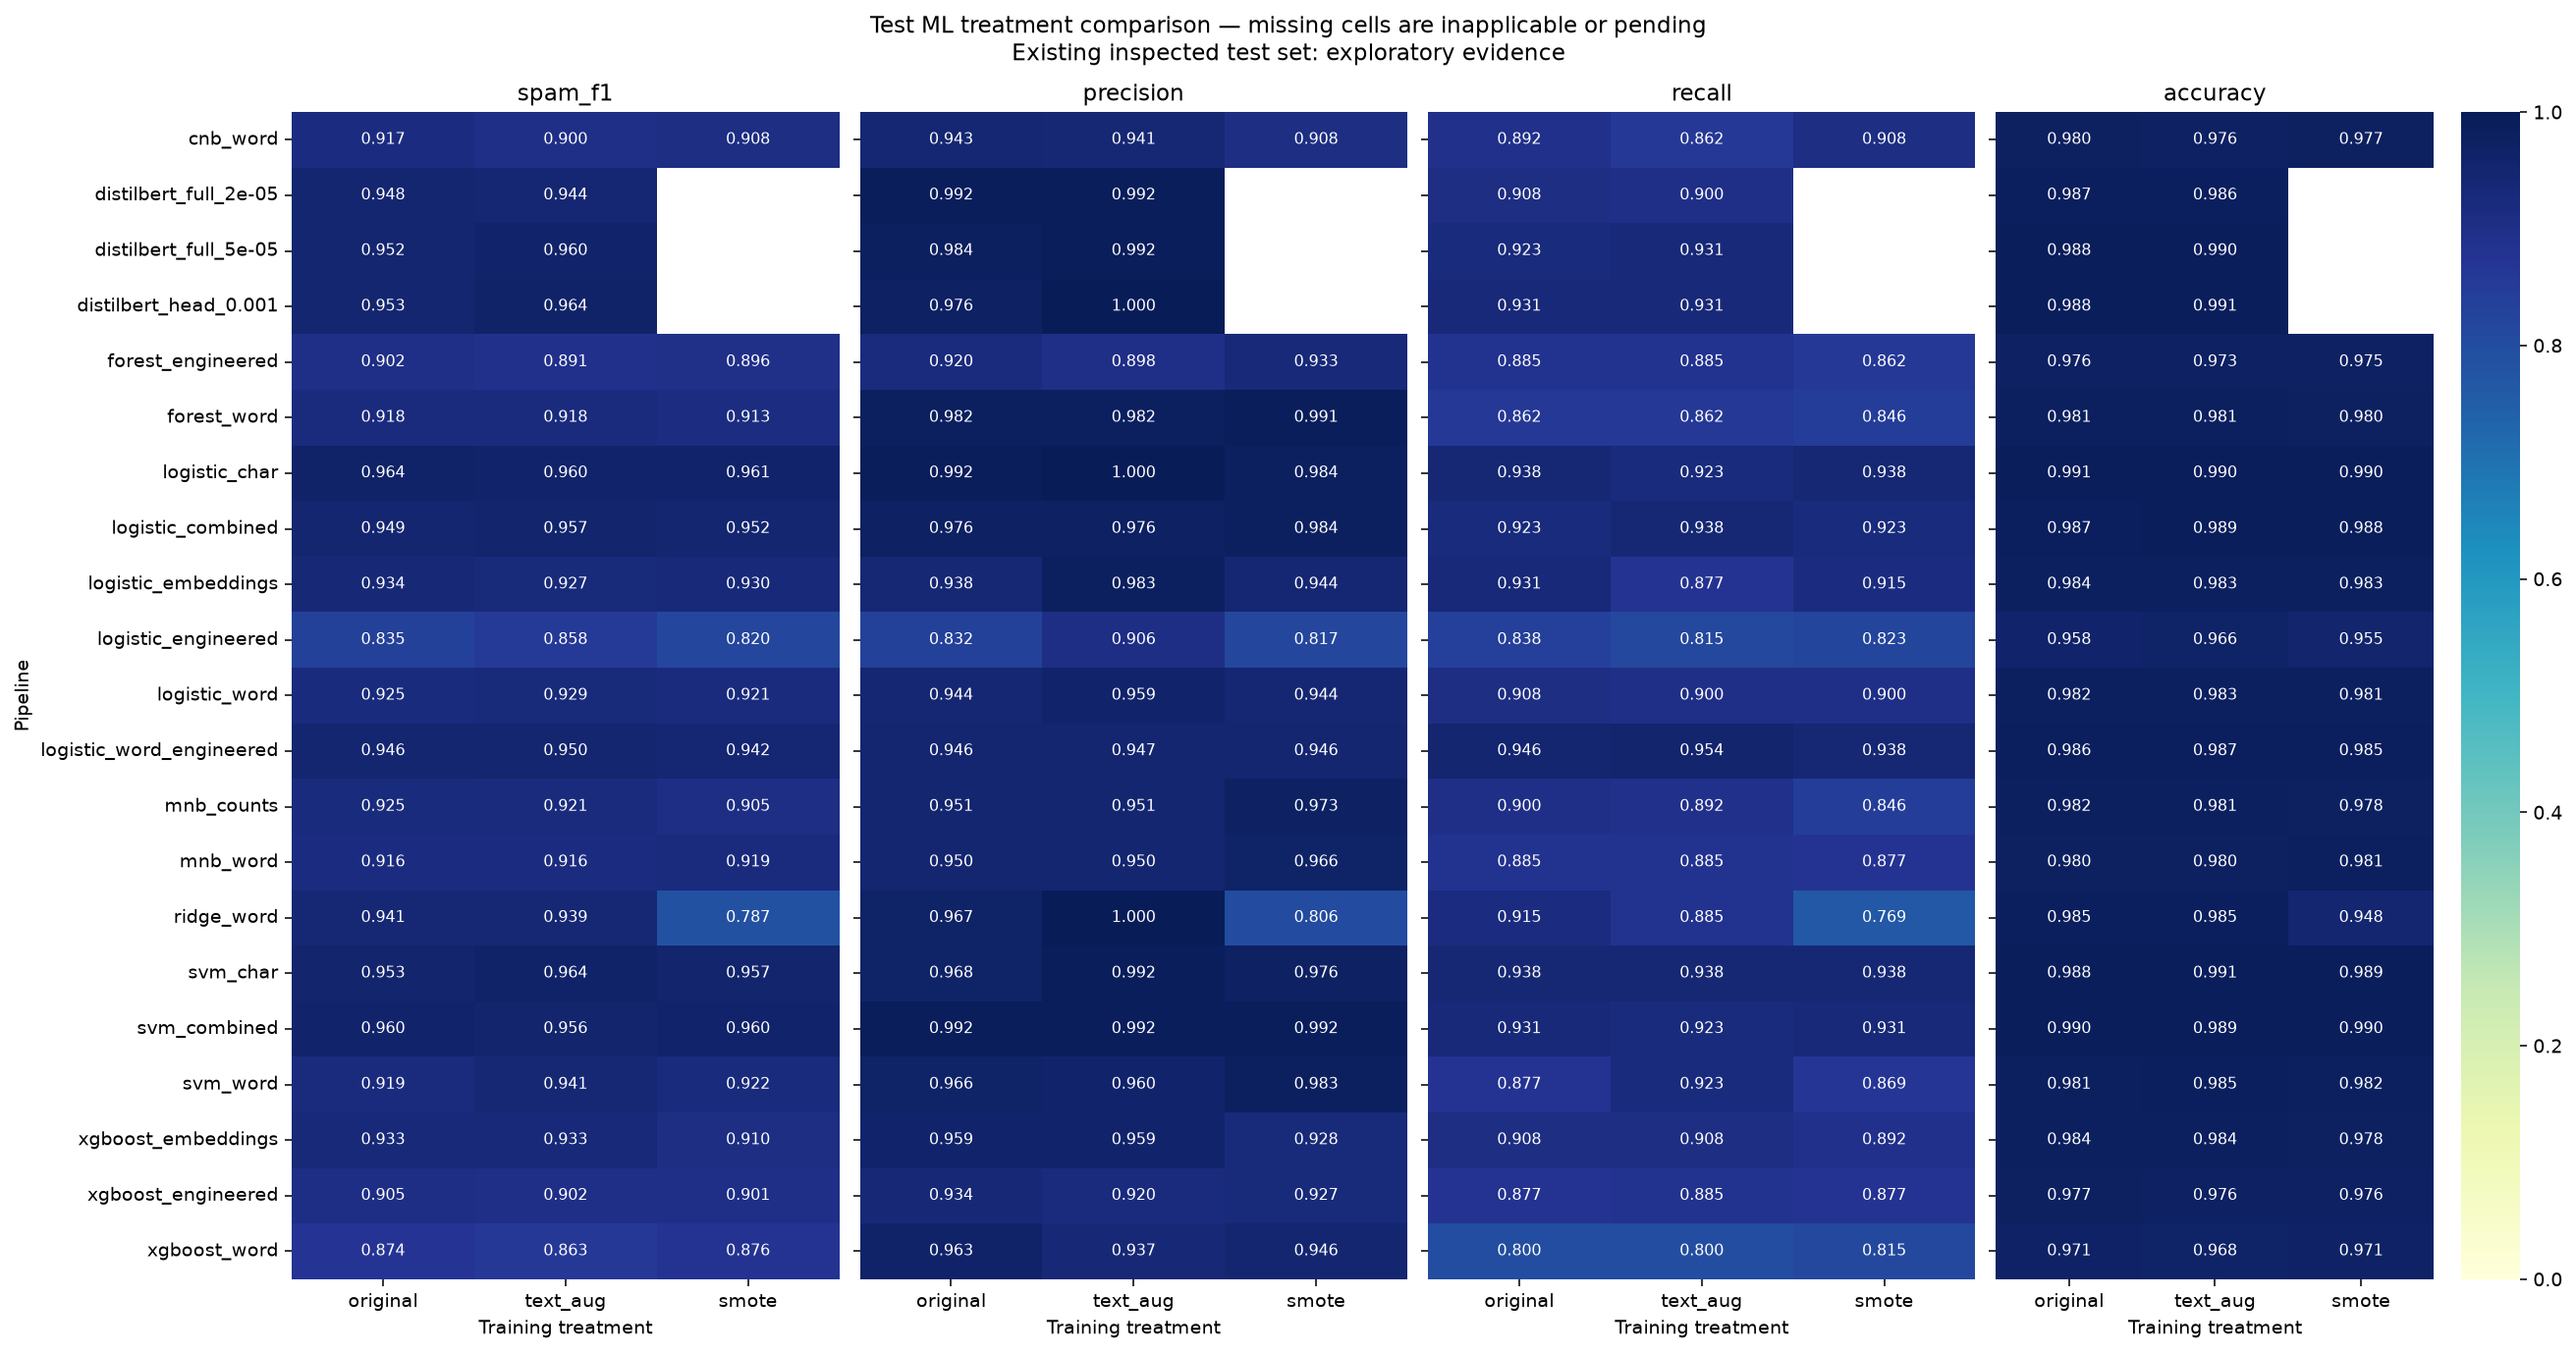

,candidate,base_candidate,treatment,delta_f1,delta_f1_ci_low,delta_f1_ci_high,repetitions,unit,scope
0,cnb_word__smote,cnb_word,smote,-0.009304,-0.037054,0.011238,500,template family,Exploratory; no multiple-comparison correction
1,cnb_word__text_aug,cnb_word,text_aug,-0.017398,-0.050755,0.017597,500,template family,Exploratory; no multiple-comparison correction
2,distilbert_full_2e-05__text_aug,distilbert_full_2e-05,text_aug,-0.004243,-0.014028,0.000000,500,template family,Exploratory; no multiple-comparison correction
3,distilbert_full_5e-05__text_aug,distilbert_full_5e-05,text_aug,0.007937,-0.012040,0.026608,500,template family,Exploratory; no multiple-comparison correction
4,distilbert_head_0.001__text_aug,distilbert_head_0.001,text_aug,0.011388,0.000000,0.025919,500,template family,Exploratory; no multiple-comparison correction
5,forest_engineered__smote,forest_engineered,smote,-0.005961,-0.023786,0.010439,500,template family,Exploratory; no multiple-comparison correction
6,forest_engineered__text_aug,forest_engineered,text_aug,-0.010488,-0.032858,0.013391,500,template family,Exploratory; no multiple-comparison correction
7,forest_word__smote,forest_word,smote,-0.005170,-0.023668,0.015517,500,template family,Exploratory; no multiple-comparison correction
8,forest_word__text_aug,forest_word,text_aug,0.000000,-0.014386,0.017115,500,template family,Exploratory; no multiple-comparison correction
9,logistic_char__smote,logistic_char,smote,-0.003797,-0.026370,0.019210,500,template family,Exploratory; no multiple-comparison correction


,stage,treatment,paired_pipelines,higher_f1,equal_f1,lower_f1,median_delta_f1
0,test,text_aug,21,8,3,10,0.000000
1,test,smote,18,5,1,12,-0.004150
2,validation,text_aug,21,10,1,10,0.000000
3,validation,smote,18,4,2,12,-0.003981


Treatment win/tie/loss counts are descriptive across these fixed pipelines, not independent replications.

In [6]:
if Path("reports/runs/augmentation/summary.json").exists():
    display(read_json("reports/runs/augmentation/summary.json"))
if Path("reports/runs/augmentation/pilot_review.json").exists():
    display(read_json("reports/runs/augmentation/pilot_review.json"))
if Path("reports/augmentation_quality_summary.json").exists():
    display(read_json("reports/augmentation_quality_summary.json"))
figure("augmentation_distributions")
if Path("reports/runs/imbalance/augmentation_fit_counts.json").exists():
    display(pd.DataFrame(read_json("reports/runs/imbalance/augmentation_fit_counts.json")).T)
if Path("reports/runs/imbalance/search_budget_audit.json").exists():
    display(read_json("reports/runs/imbalance/search_budget_audit.json"))
if Path("reports/runs/imbalance/encoder_pair_audit.json").exists():
    audit = read_json("reports/runs/imbalance/encoder_pair_audit.json")
    display(
        pd.DataFrame(
            [
                {"setting": name, "treatment": treatment, **policy}
                for name, arms in audit.items()
                for treatment, policy in arms.items()
            ]
        )
    )
for history in sorted(Path("reports/runs/imbalance/encoder").glob("*/history.json")):
    display(Markdown("Encoder history: " + history.parent.name))
    display(pd.DataFrame(read_json(history)))
if Path("reports/ml_treatment_comparison.csv").exists():
    display(pd.read_csv("reports/ml_treatment_comparison.csv"))
figure("ml_treatments_validation")
figure("ml_treatments_test")
if Path("reports/ml_treatment_paired_differences.csv").exists():
    display(pd.read_csv("reports/ml_treatment_paired_differences.csv"))
if Path("reports/ml_treatment_effect_summary.csv").exists():
    display(pd.read_csv("reports/ml_treatment_effect_summary.csv"))
    display(
        Markdown(
            "Treatment win/tie/loss counts are descriptive across these fixed pipelines, not independent replications."
        )
    )

## Hosted generative and decision models

Seven LLMs compare zero-shot and fixed four-example few-shot prompts. Examples come from training only. Supported reasoning/output controls are logged. Seven decision models compare explicit `choice` with binary `noul`, using equivalent class definitions. Validation picks one configuration per model. For decision probabilities, validation selects an operating threshold.

Typed output is not a guarantee of correctness or calibration. Luna's generative and decision interfaces are related, so they are not independent underlying model families. Microsoft's decision model is Qwen-derived and may update behind a stable API. Catalog availability is verified separately from actual successful inference.

A budget ledger reserves conservative costs before requests and retains unknown charges. The authorized cap is US$10 total, including a US$1 pilot. Pilot accuracy is not a meaningful ranking; development selection and final evaluation use larger partitions.

In [7]:
display(read_json("configs/candidates.json"))
if Path("reports/candidate_availability.json").exists():
    available = read_json("reports/candidate_availability.json")
    display(
        pd.DataFrame(
            [
                {
                    "group": group,
                    "model": model,
                    "listed": info["listed"],
                    "pricing": info["pricing"],
                }
                for group, models in available.items()
                for model, info in models.items()
            ]
        )
    )
for stage in ["development", "validation"]:
    path = Path("reports/runs") / stage / "results.json"
    if path.exists():
        display(
            pd.DataFrame(
                [
                    {
                        "model": r["candidate"],
                        "variant": r["variant"],
                        "n": r["record_count"],
                        "f1": r["metrics"].get("spam_f1"),
                        "coverage": r["metrics"]["coverage"],
                        "cost_usd": r["cost_usd"],
                        "p95_ms": r["latency"]["p95_ms"],
                    }
                    for r in read_json(path)
                ]
            )
        )

{'llm': ['openai/gpt-6-luna',
  'anthropic/claude-haiku-5.5',
  'qwen/qwen3.8-flash',
  'google/gemini-4-hydrogen',
  'openai/gpt-6.1-sol',
  'deepseek/deepseek-v4.1-flash-1017',
  'meta/muse-ember'],
 'decision': ['typesafe/jev-1.14',
  'perplexity/pplx-decider-v1.3:free',
  'nace-ai/drex-v2.0',
  'liquid/d1-ultra',
  'google/gemini-decision-1',
  'openai/gpt-6-luna-decisions',
  'microsoft/microsoft-decision-1']}

,group,model,listed,pricing
0,llm,openai/gpt-6-luna,True,"{'prompt': '0.0000001', 'completion': '0.00000..."
1,llm,anthropic/claude-haiku-5.5,True,"{'prompt': '0.0000001', 'completion': '0.00000..."
2,llm,qwen/qwen3.8-flash,True,"{'prompt': '0.00000015', 'completion': '0.0000..."
3,llm,google/gemini-4-hydrogen,True,"{'prompt': '0.0000015', 'completion': '0.00000..."
4,llm,openai/gpt-6.1-sol,True,"{'prompt': '0.000002', 'completion': '0.00001'..."
5,llm,deepseek/deepseek-v4.1-flash-1017,True,"{'prompt': '0.00000002', 'completion': '0.0000..."
6,llm,meta/muse-ember,True,"{'prompt': '0.0000001', 'completion': '0.00000..."
7,decision,typesafe/jev-1.14,True,"{'prompt': '0.000000042', 'completion': '0'}"
8,decision,perplexity/pplx-decider-v1.3:free,True,"{'prompt': '0', 'completion': '0'}"
9,decision,nace-ai/drex-v2.0,True,"{'prompt': '0.00000006', 'completion': '0'}"


,model,variant,n,f1,coverage,cost_usd,p95_ms
0,openai/gpt-6-luna,zero_shot,96,0.869565,1.000000,0.002216,1570.452918
1,openai/gpt-6-luna,few_shot,96,0.909091,1.000000,0.003905,1867.058352
2,anthropic/claude-haiku-5.5,zero_shot,96,0.833333,1.000000,0.004579,1723.364608
3,anthropic/claude-haiku-5.5,few_shot,96,0.846154,1.000000,0.006739,1846.871979
4,qwen/qwen3.8-flash,zero_shot,96,0.916667,1.000000,0.002389,1377.956639
5,qwen/qwen3.8-flash,few_shot,96,0.916667,1.000000,0.002050,776.104813
6,google/gemini-4-hydrogen,zero_shot,96,0.869565,1.000000,0.115840,1600.512081
7,google/gemini-4-hydrogen,few_shot,96,0.909091,1.000000,0.131066,1797.242342
8,openai/gpt-6.1-sol,zero_shot,96,0.909091,1.000000,0.045172,3225.960991
9,openai/gpt-6.1-sol,few_shot,96,0.909091,1.000000,0.078104,2578.140363


,model,variant,n,f1,coverage,cost_usd,p95_ms
0,openai/gpt-6-luna,few_shot,1035,0.942085,1.000000,0.042288,1895.795207
1,anthropic/claude-haiku-5.5,few_shot,1035,0.837209,1.000000,0.072879,1626.798696
2,qwen/qwen3.8-flash,few_shot,1035,0.937729,1.000000,0.022395,942.501003
3,google/gemini-4-hydrogen,few_shot,1035,0.964427,1.000000,1.430446,1709.754331
4,openai/gpt-6.1-sol,zero_shot,1035,0.952756,1.000000,0.493402,2941.732809
5,deepseek/deepseek-v4.1-flash-1017,zero_shot,1035,0.939394,1.000000,0.018108,1197.403448
6,meta/muse-ember,few_shot,1035,0.933333,1.000000,0.125851,1621.151400
7,typesafe/jev-1.14,noul,1035,0.957529,1.000000,0.016922,548.067001
8,perplexity/pplx-decider-v1.3:free,choice,1035,0.996169,1.000000,0.000000,907.059585
9,nace-ai/drex-v2.0,noul,1035,0.958678,0.936232,0.006403,957.835659


## Final held-out comparison

The table below is test performance only. Selections are recorded in configuration files before test execution. Report raw counts, class support, F1, precision/recall, average precision, calibration where applicable, latency, coverage, and cost. SVM/Ridge decision scores are not calibrated probabilities. Brier score is the mean squared error between P(spam) and the 0/1 label; lower is better. Reliability plots compare mean predicted probability with observed spam fraction and display bin counts. Local inference latency includes preprocessing; embedding inference includes encoding. Hosted latency includes network overhead.

p50 is the median; p95 is the time within which 95% of measured requests finish. Local timings use warm sequential requests on the recorded machine; hosted experiments state concurrency. These are practical system measurements, not isolated hardware-speed comparisons.

Separate precision, recall, and accuracy charts compare local models/baseline, LLMs, and decision models in three panels on a common scale. Hosted classification metrics are conditional on successful responses; labels show coverage so unavailable predictions are visible. The always-ham baseline has zero spam recall despite high accuracy. Zero predicted spam is reported as precision zero by convention.

,candidate,group,variant,stage,source_stage,evaluation_scope,measurement_concurrency,latency_scope,attempted,completed,coverage,end_to_end_accuracy,...,usd_per_1000_completed,projected_reported_usd_per_million,cost_projection_note,unknown_cost_attempts,observed_messages_per_second,p50_ms,p95_ms,mean_ms,count,average_precision,brier,log_loss
0,always_ham,baseline,default,test,test,Preselected historical benchmark,1,local_pipeline,1034,1034,1.000000,0.874275,...,NaN,NaN,Same workload/cache/pricing; excludes unknown ...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,perplexity/pplx-decider-v1.3:free,decision,choice,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1034,1.000000,0.997099,...,0.000000,0.000000,Same workload/cache/pricing; excludes unknown ...,0,4.272362,480.365854,960.129804,566.947978,1034.0,0.999481,0.002939,0.018129
14,microsoft/microsoft-decision-1,decision,noul,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1034,1.000000,0.990329,...,0.005145,5.145284,Same workload/cache/pricing; excludes unknown ...,0,10.033682,550.238850,633.358899,564.268298,1034.0,0.982841,0.007883,0.036578
11,liquid/d1-ultra,decision,choice,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1024,0.990329,0.976789,...,0.005221,5.170265,Same workload/cache/pricing; excludes unknown ...,10,2.660768,945.268132,3890.278977,1395.777521,1034.0,0.979100,0.029054,0.117074
8,typesafe/jev-1.14,decision,noul,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1034,1.000000,0.982592,...,0.016331,16.330810,Same workload/cache/pricing; excludes unknown ...,0,11.532985,466.310355,566.211436,478.050166,1034.0,0.975831,0.016886,0.079306
13,openai/gpt-6-luna-decisions,decision,choice,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1032,0.998066,0.980658,...,0.019317,19.279594,Same workload/cache/pricing; excludes unknown ...,2,10.952391,510.227680,577.932508,516.327751,1034.0,0.950262,0.016010,0.077955
12,google/gemini-decision-1,decision,noul,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1032,0.998066,0.978723,...,0.020071,20.031818,Same workload/cache/pricing; excludes unknown ...,2,8.870608,619.903691,780.304585,628.618422,1034.0,0.978735,0.018910,0.084979
10,nace-ai/drex-v2.0,decision,noul,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,989,0.956480,0.938104,...,0.006591,6.304294,Same workload/cache/pricing; excludes unknown ...,45,7.908744,600.165140,967.681400,653.696195,1034.0,0.978044,0.015436,0.064372
4,google/gemini-4-hydrogen,llm,few_shot,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1034,1.000000,0.989362,...,1.380646,1380.645551,Same workload/cache/pricing; excludes unknown ...,0,4.623543,1248.263460,1684.121558,1287.878643,1034.0,NaN,NaN,NaN
5,openai/gpt-6.1-sol,llm,zero_shot,test,test,Preselected historical benchmark,8,hosted_HTTP_request,1034,1034,1.000000,0.989362,...,0.473532,473.531915,Same workload/cache/pricing; excludes unknown ...,0,2.338243,1897.997332,2729.593520,2012.666434,1034.0,NaN,NaN,NaN


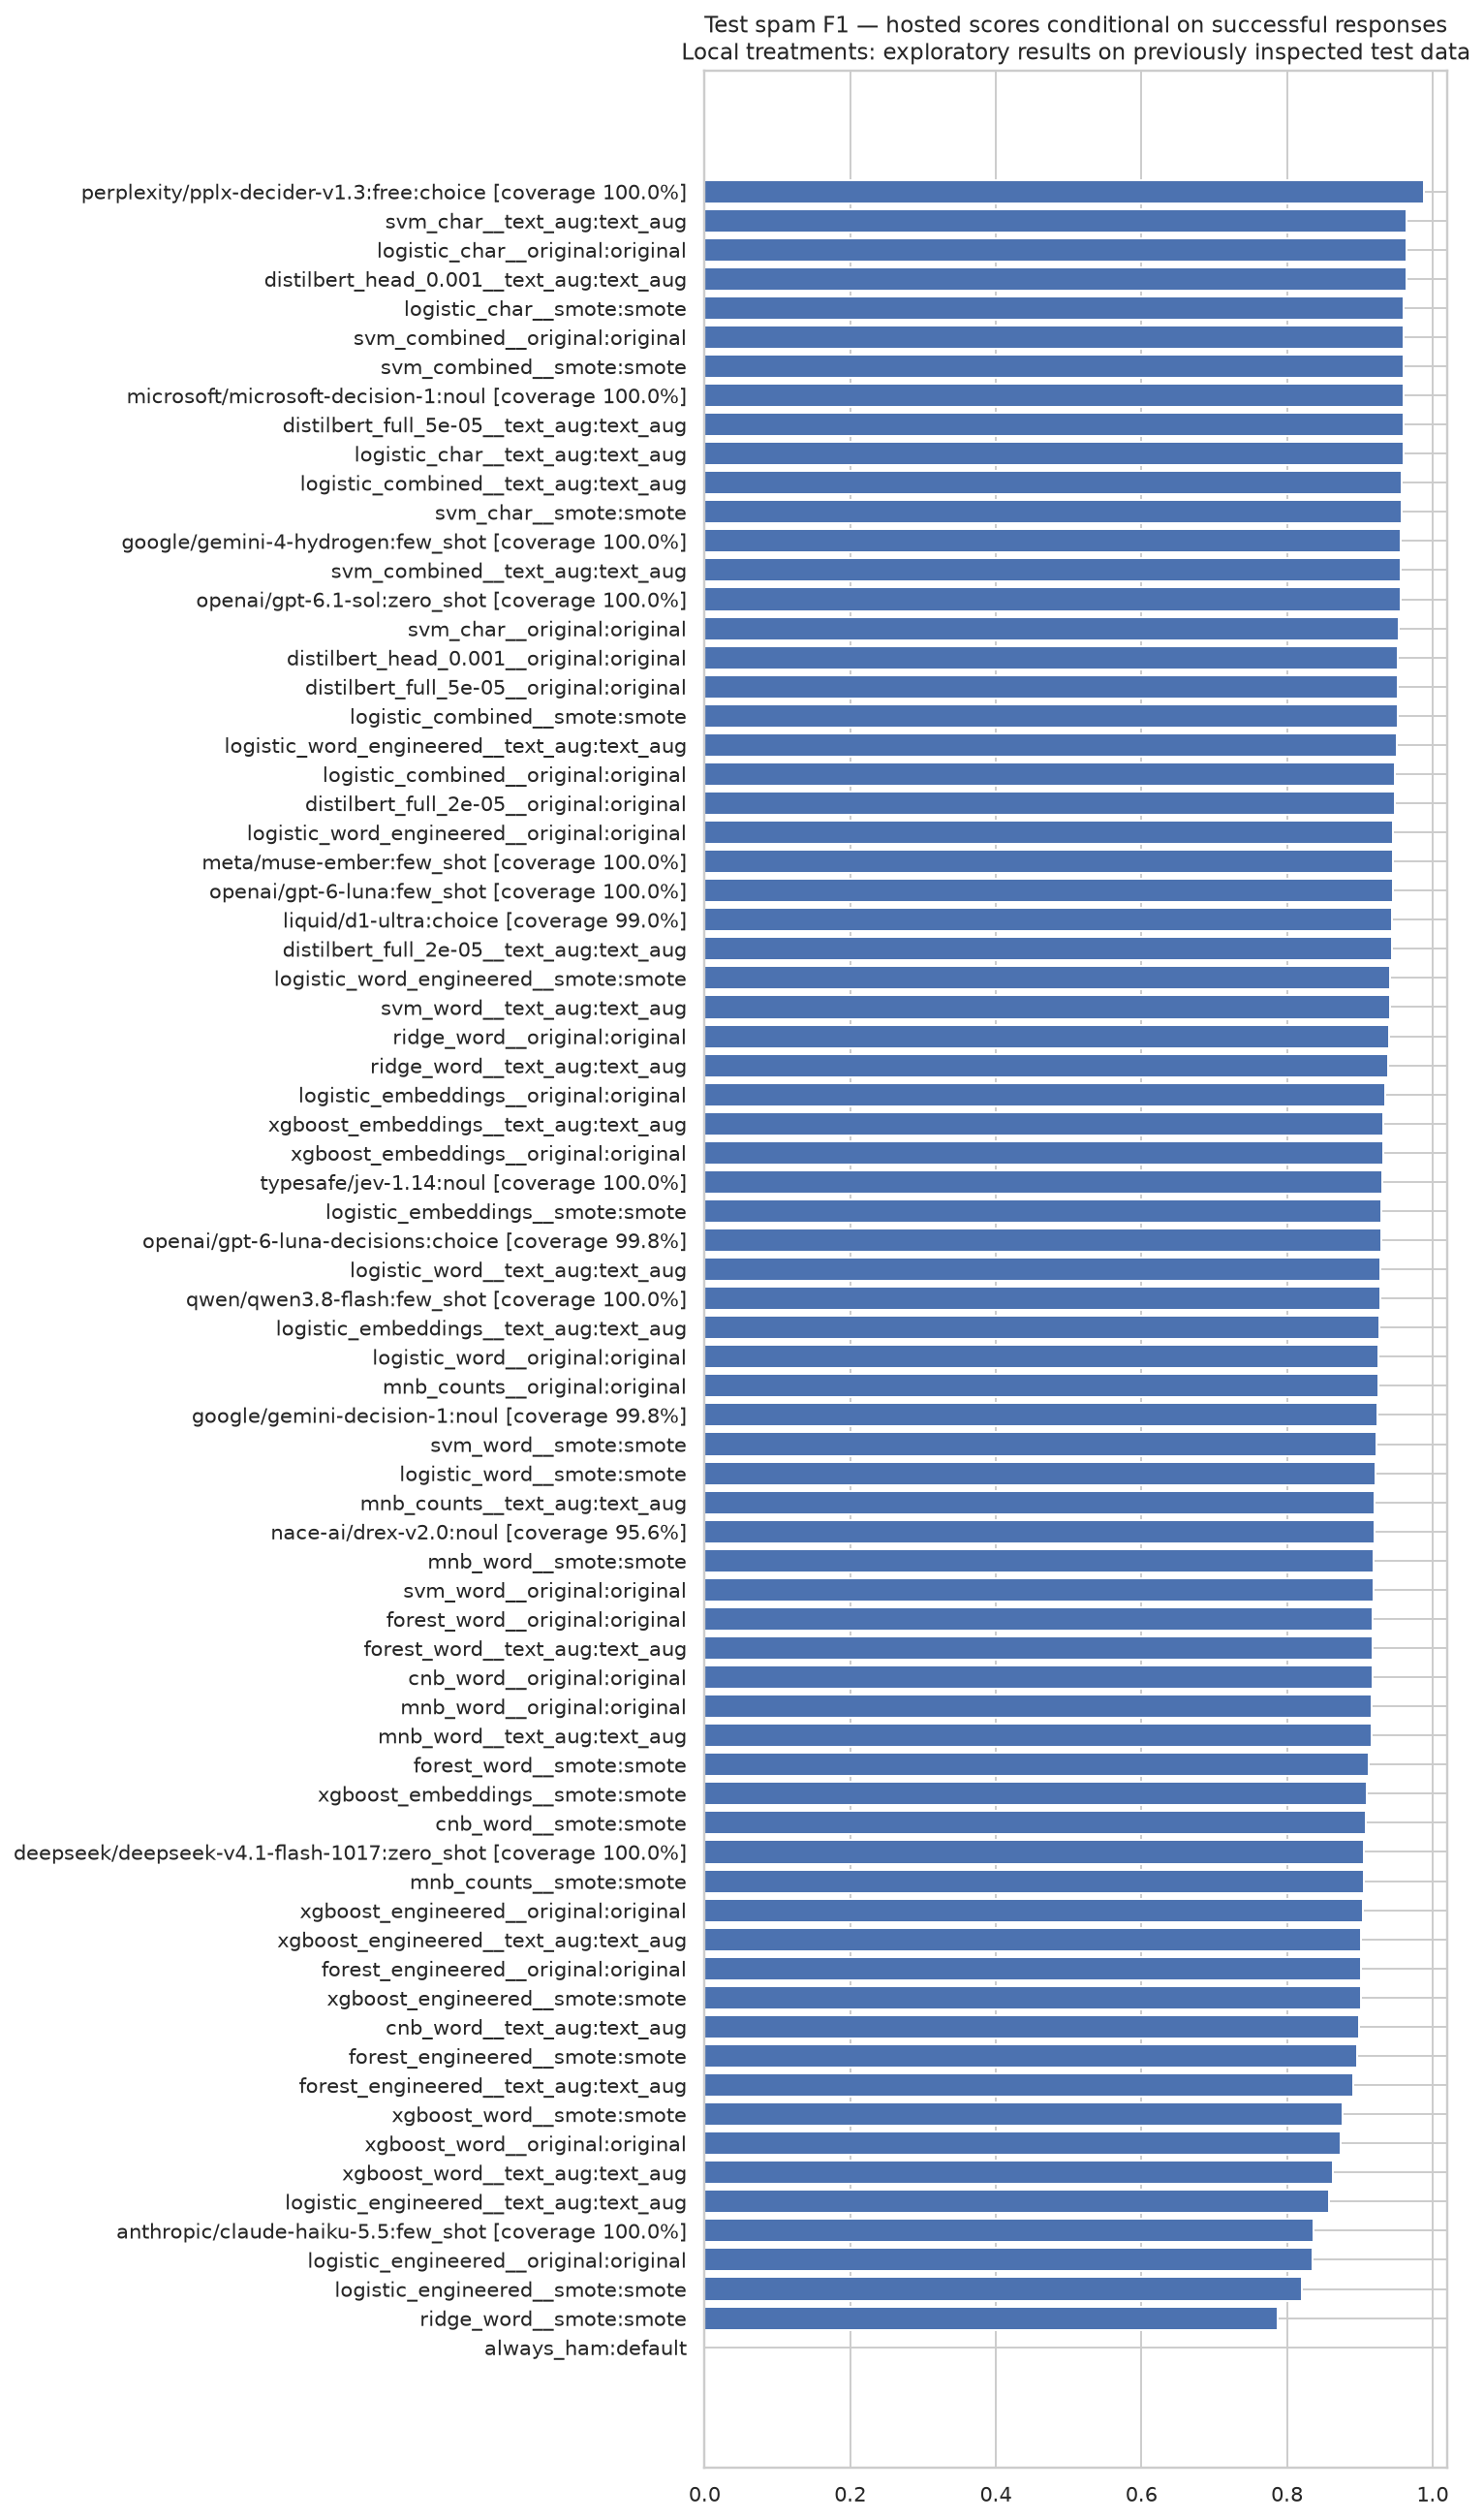

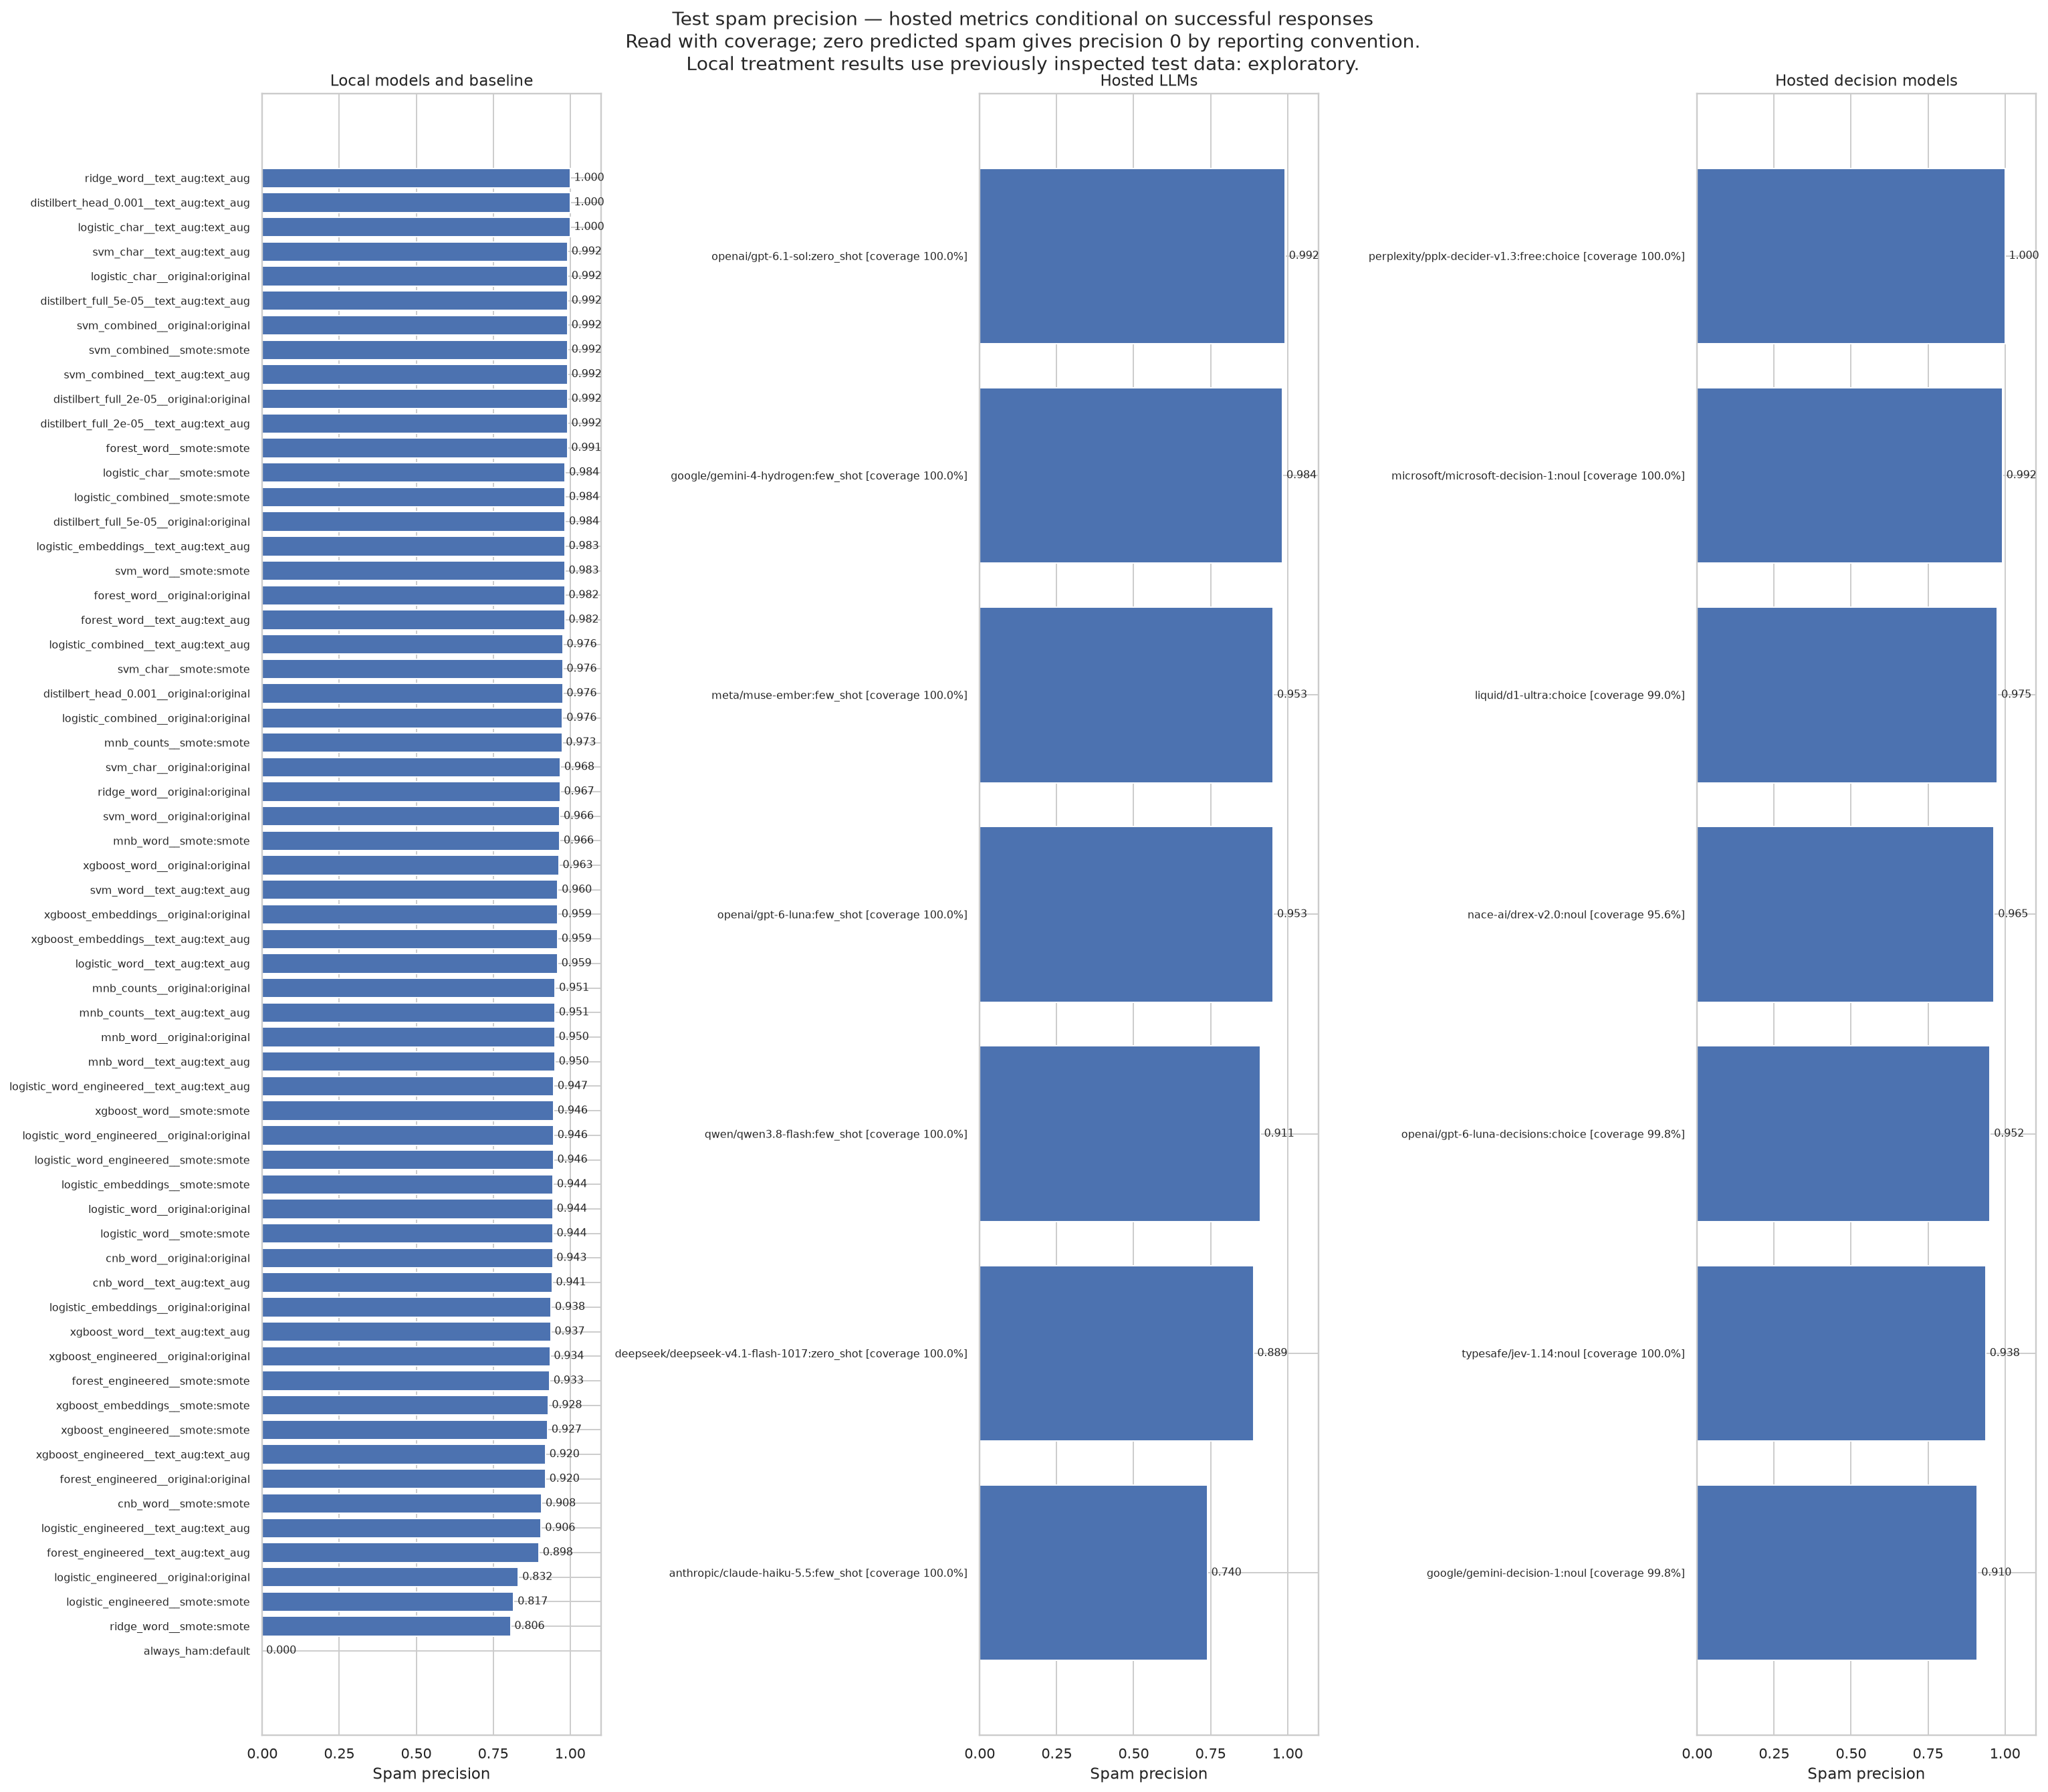

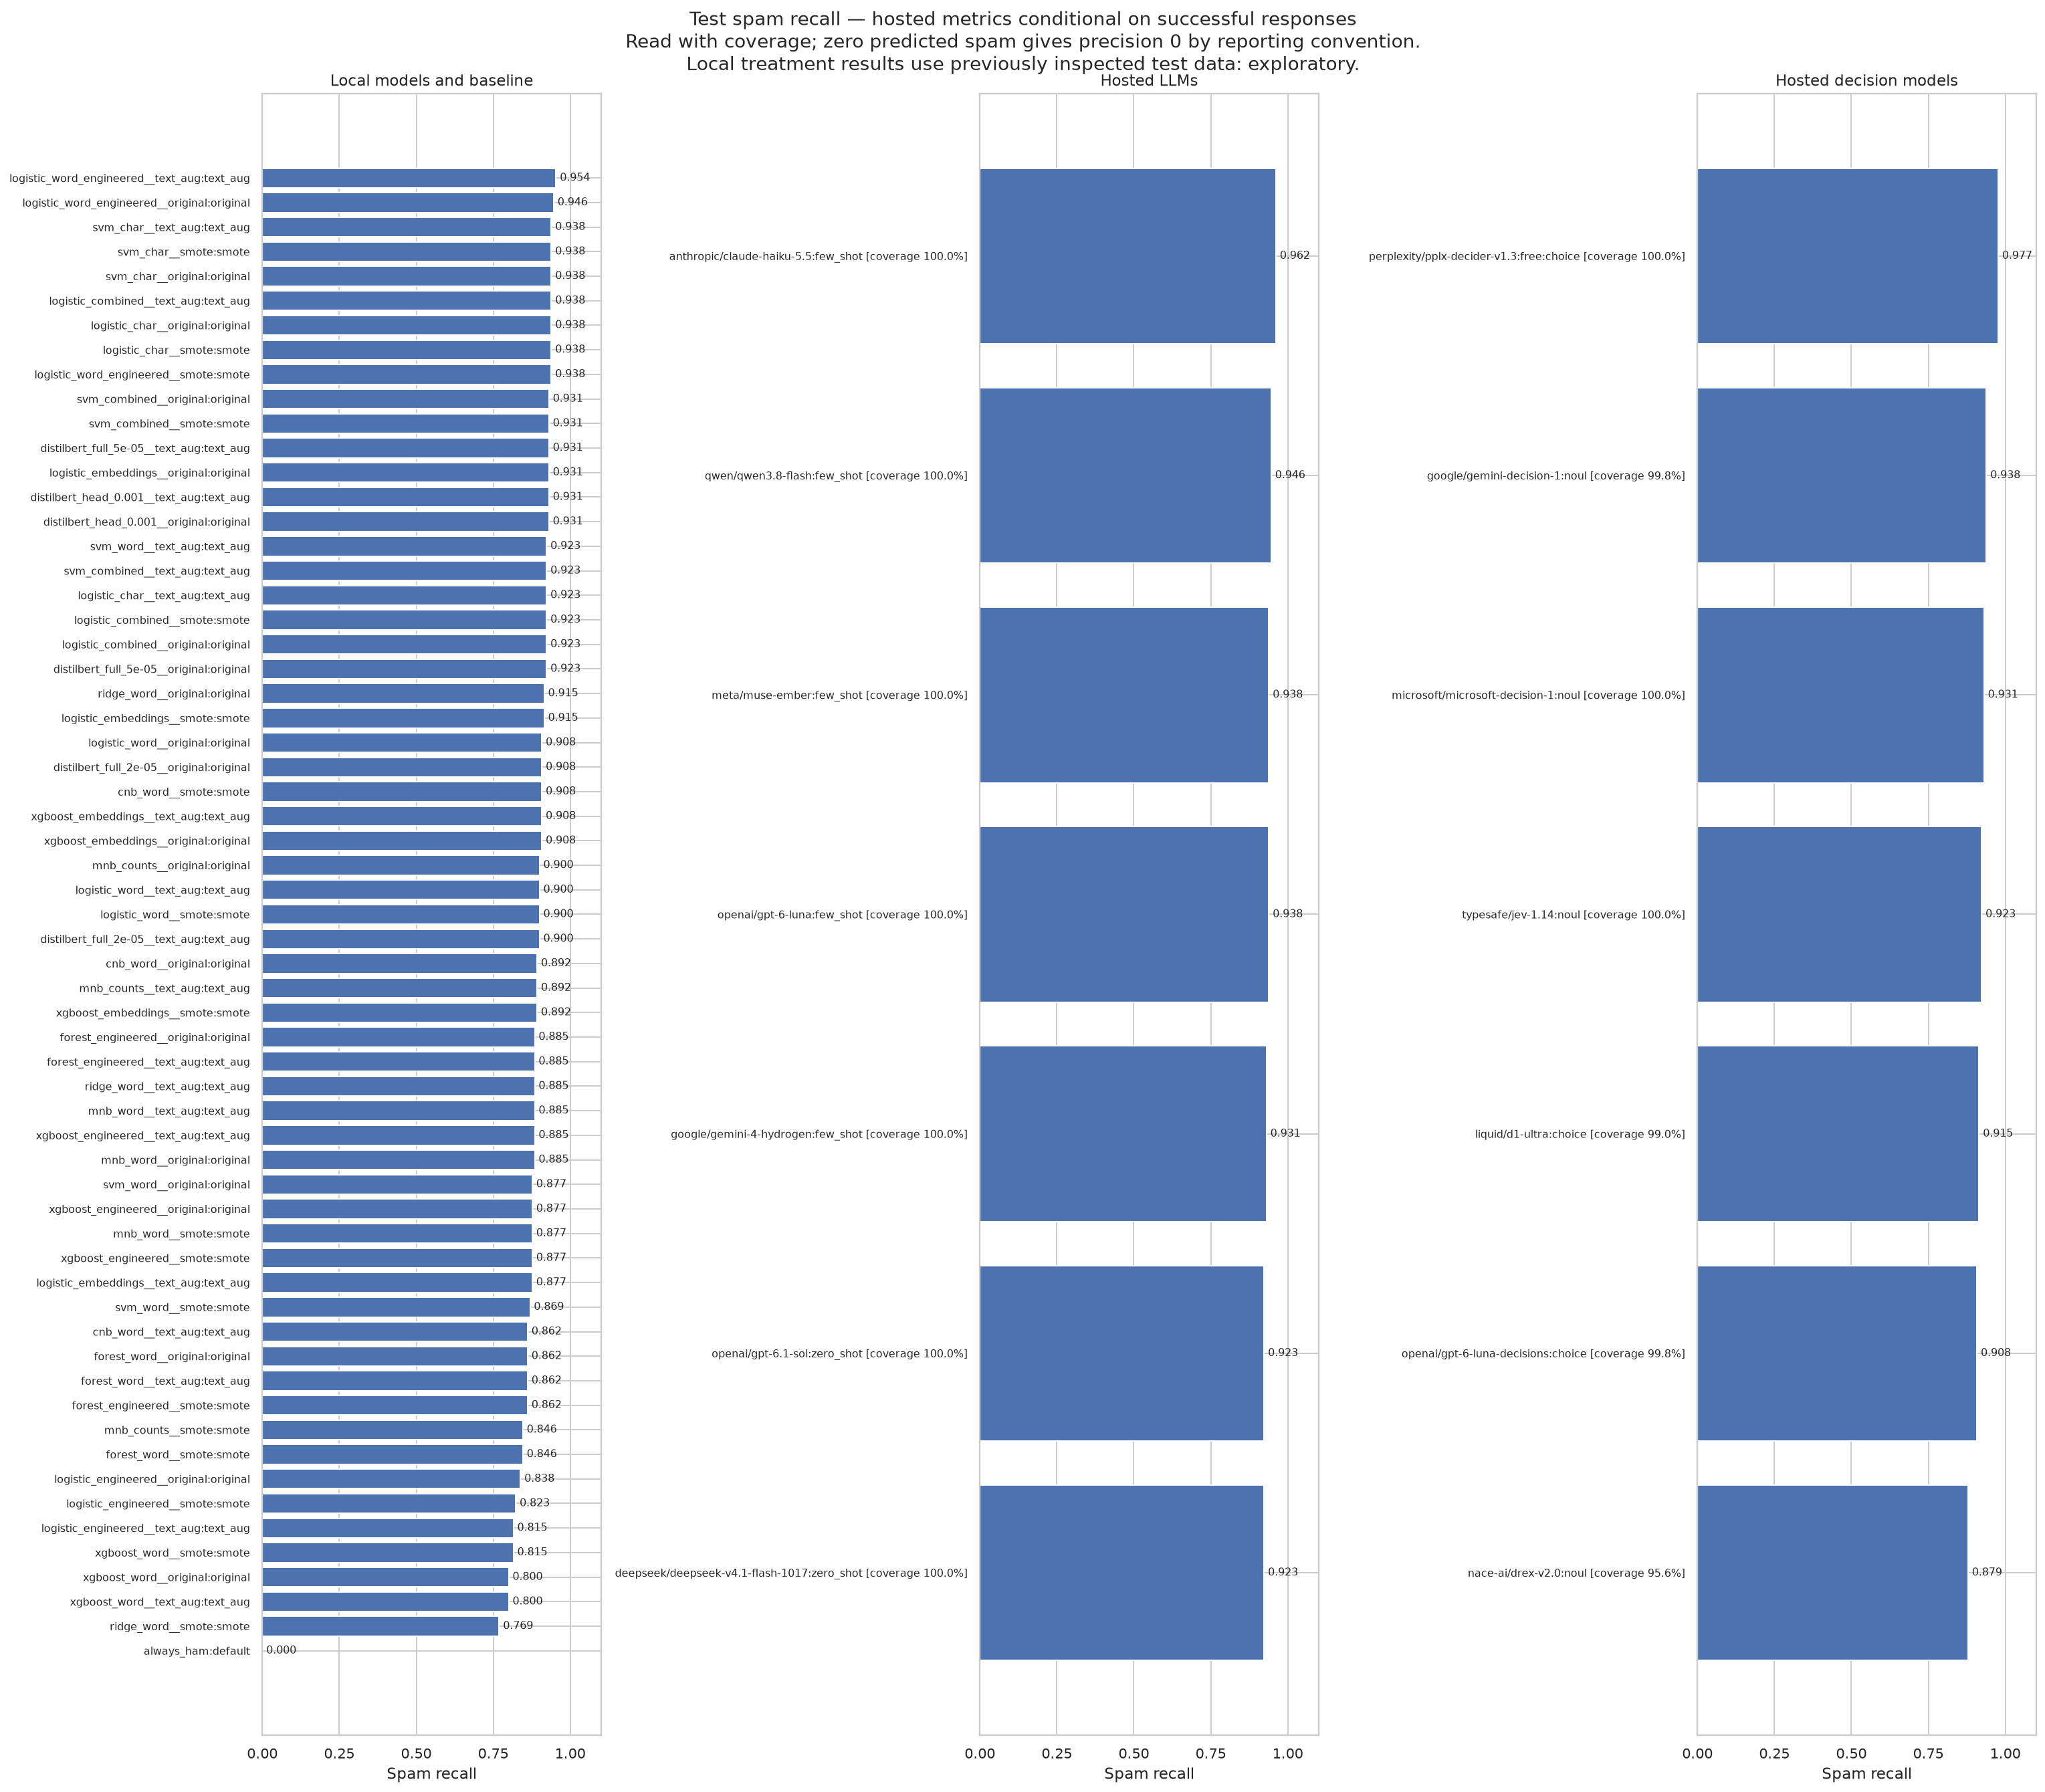

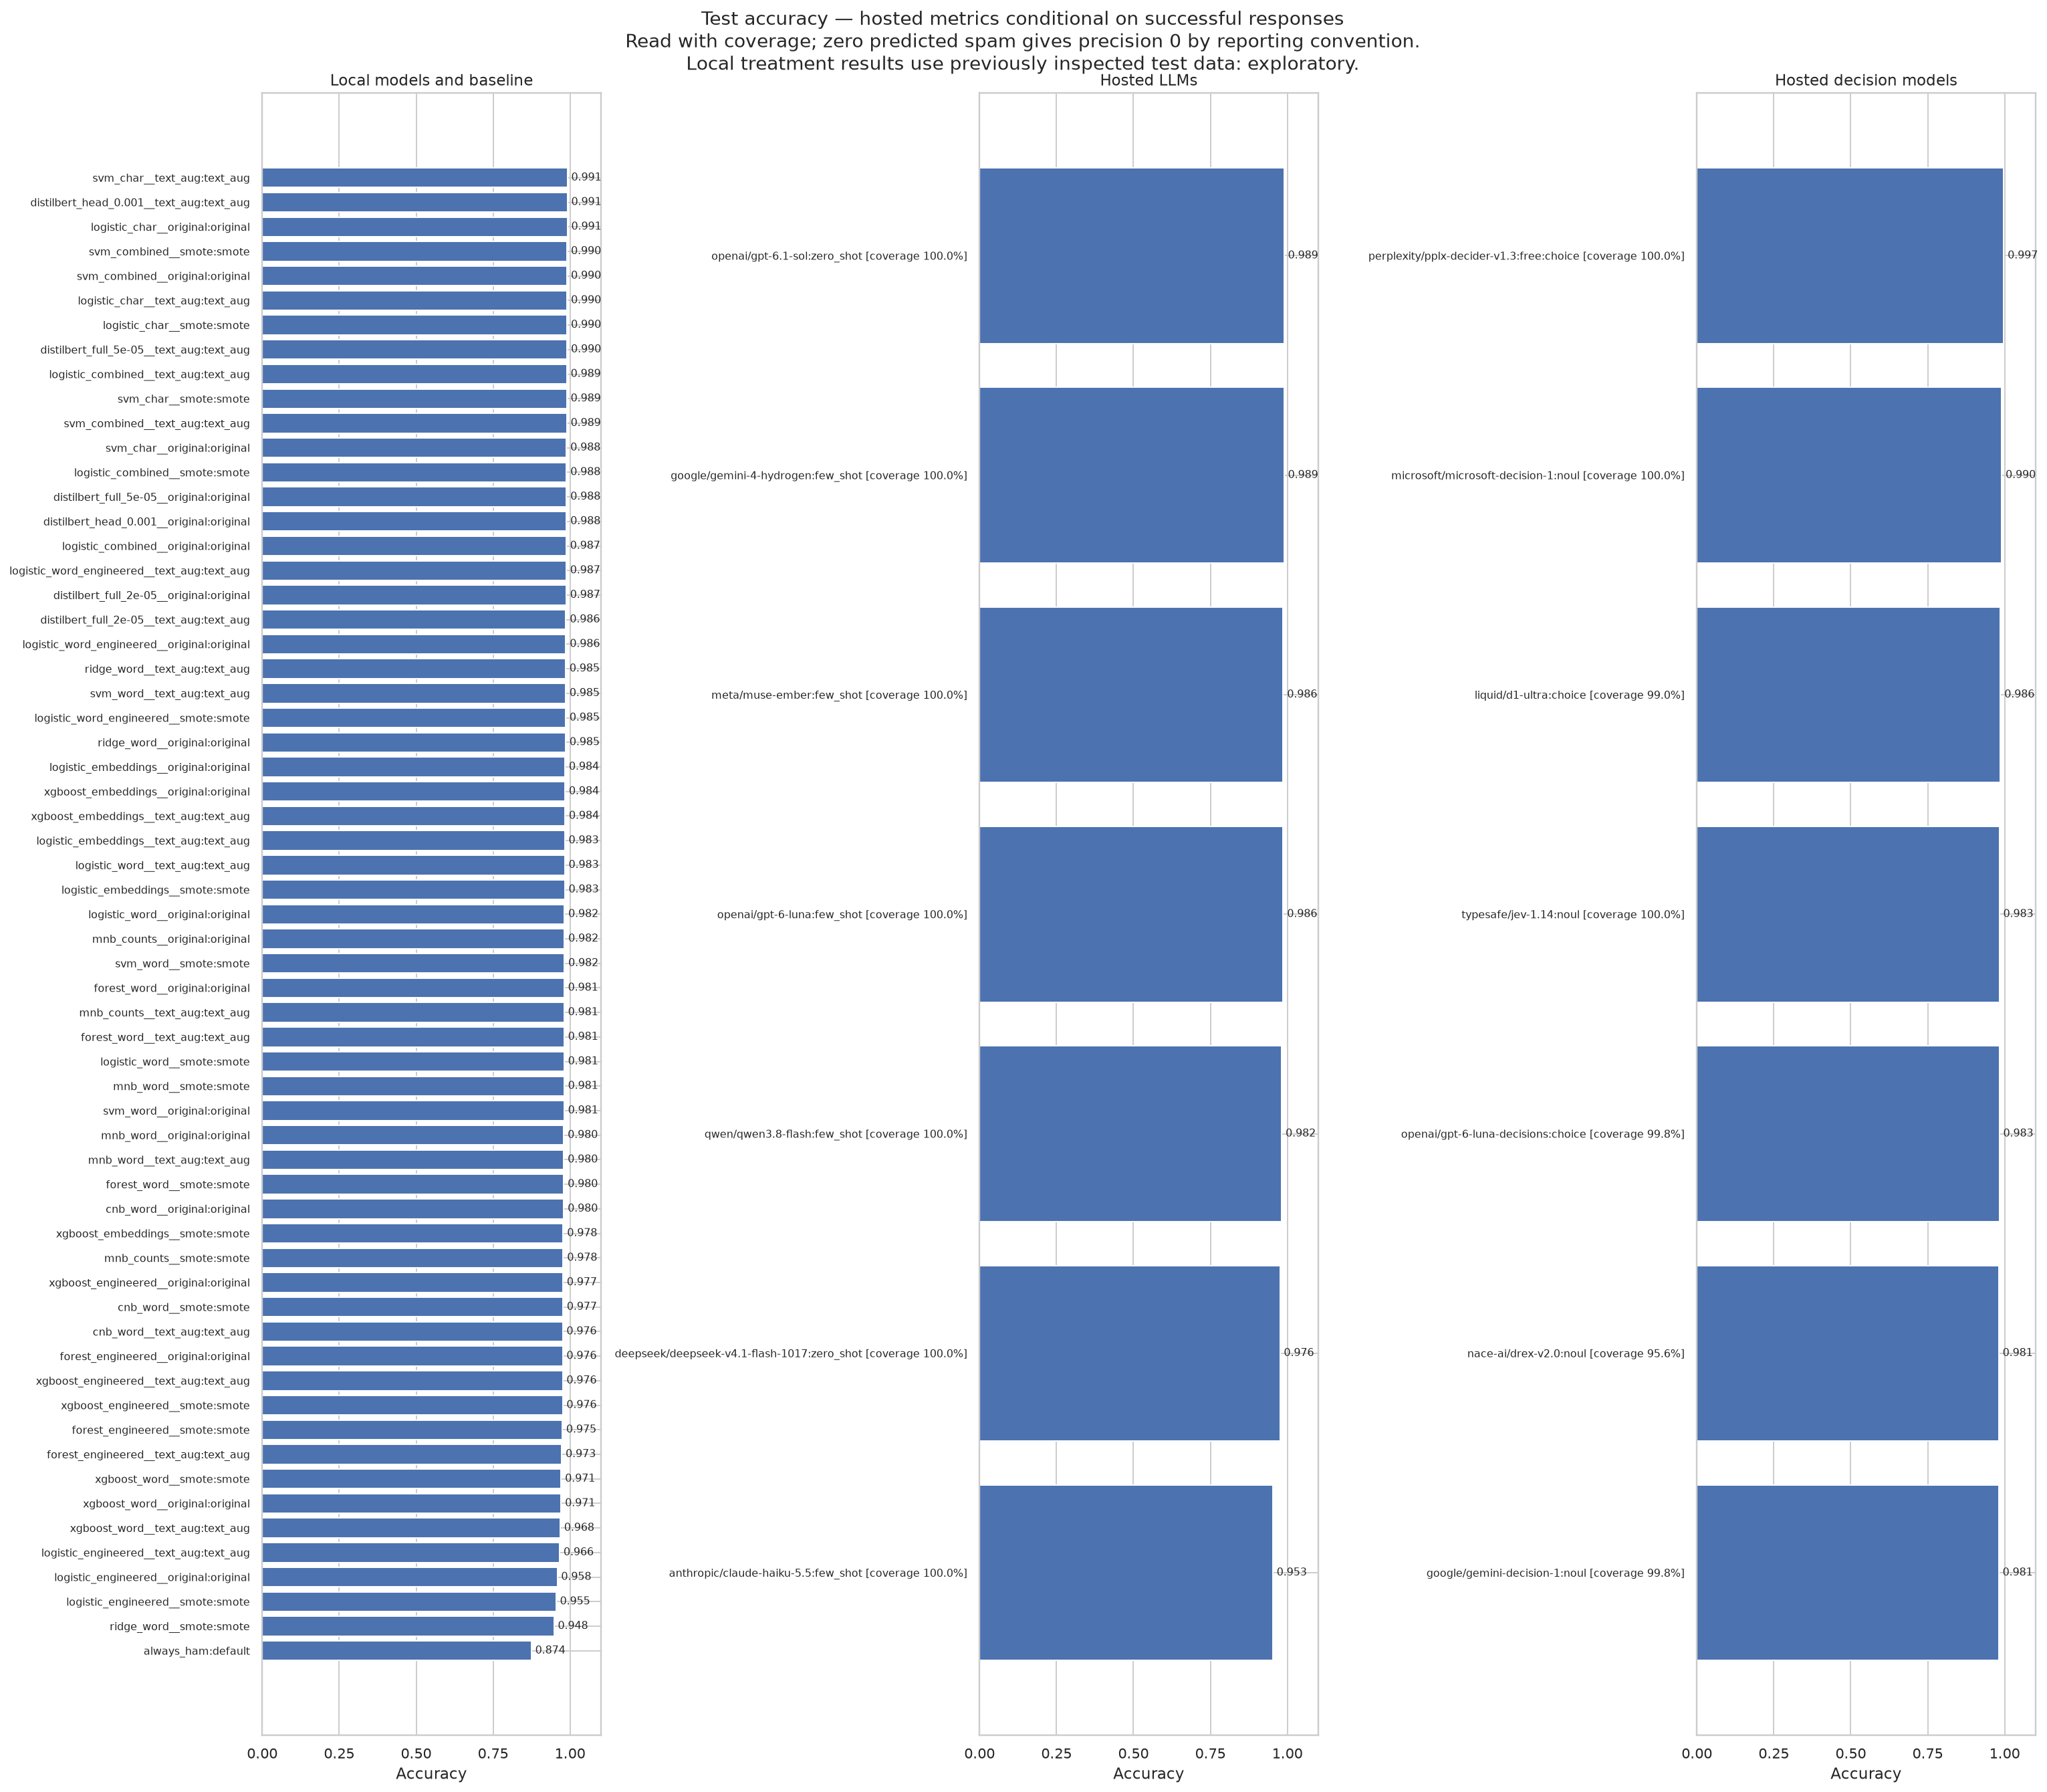

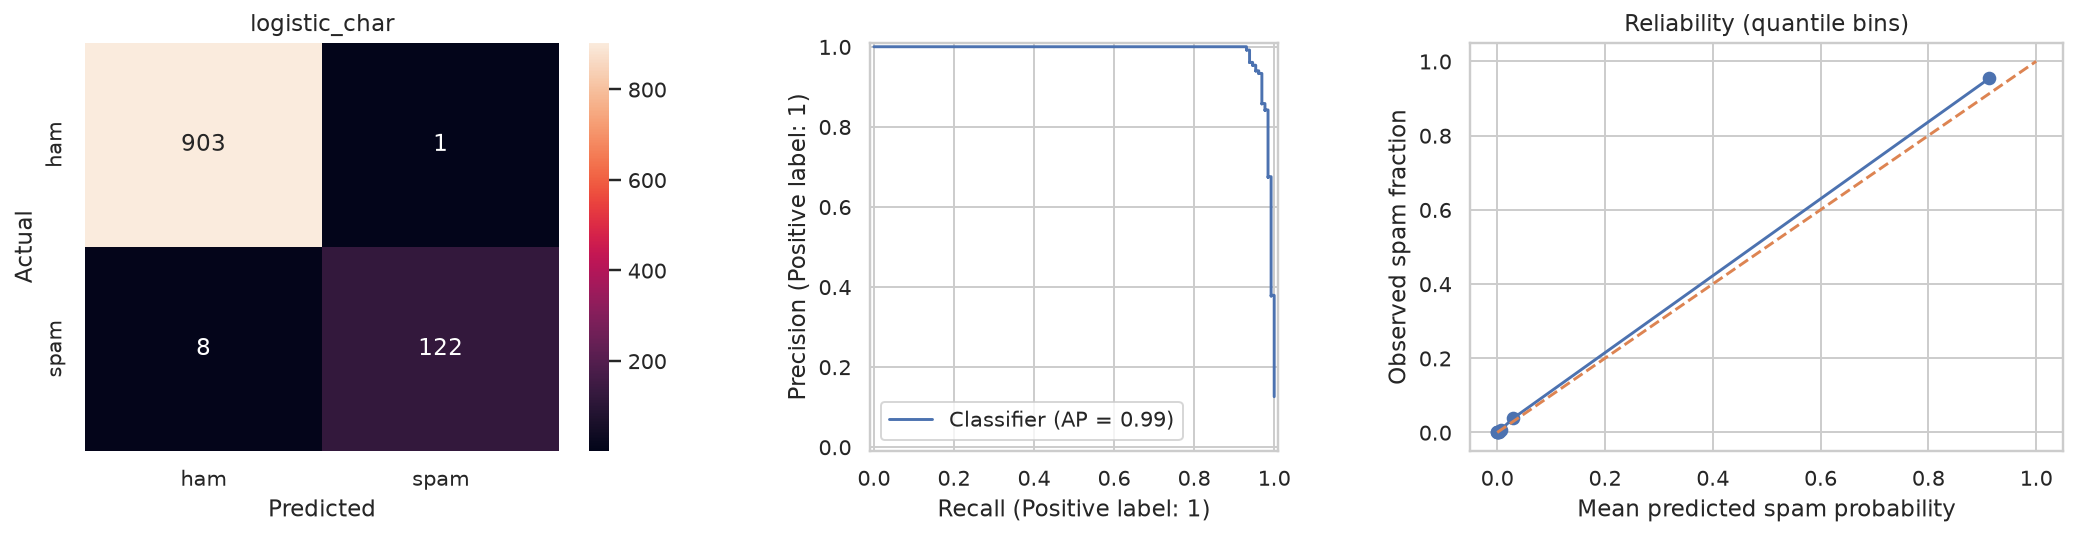

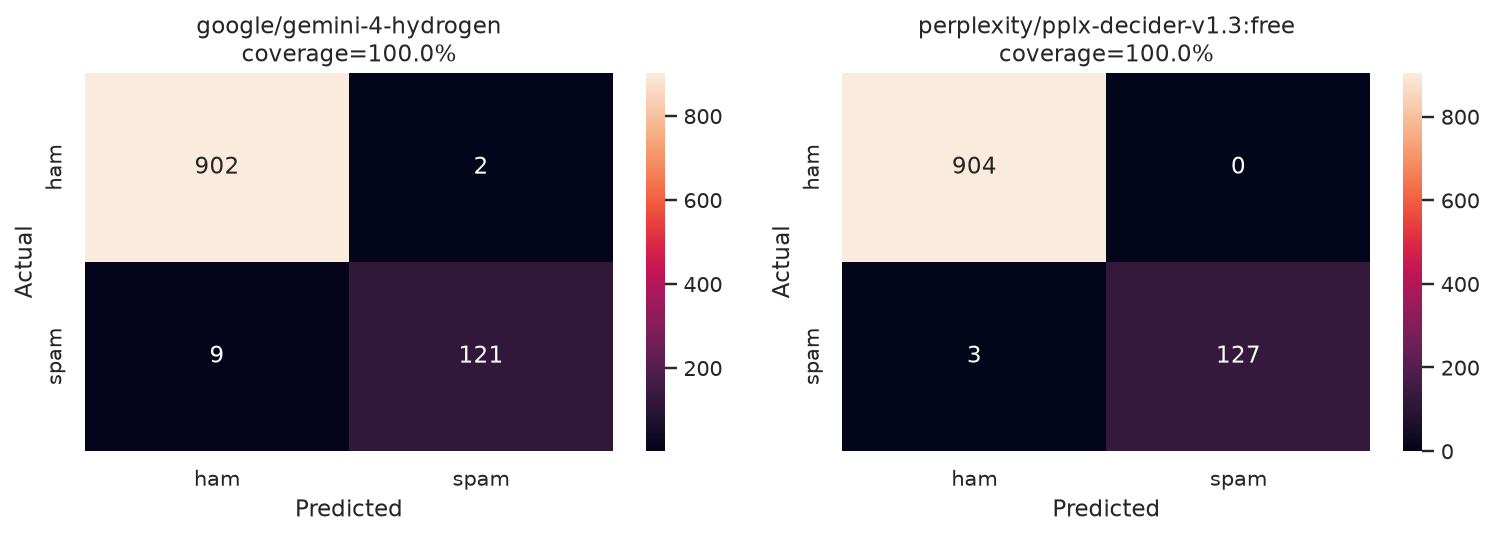

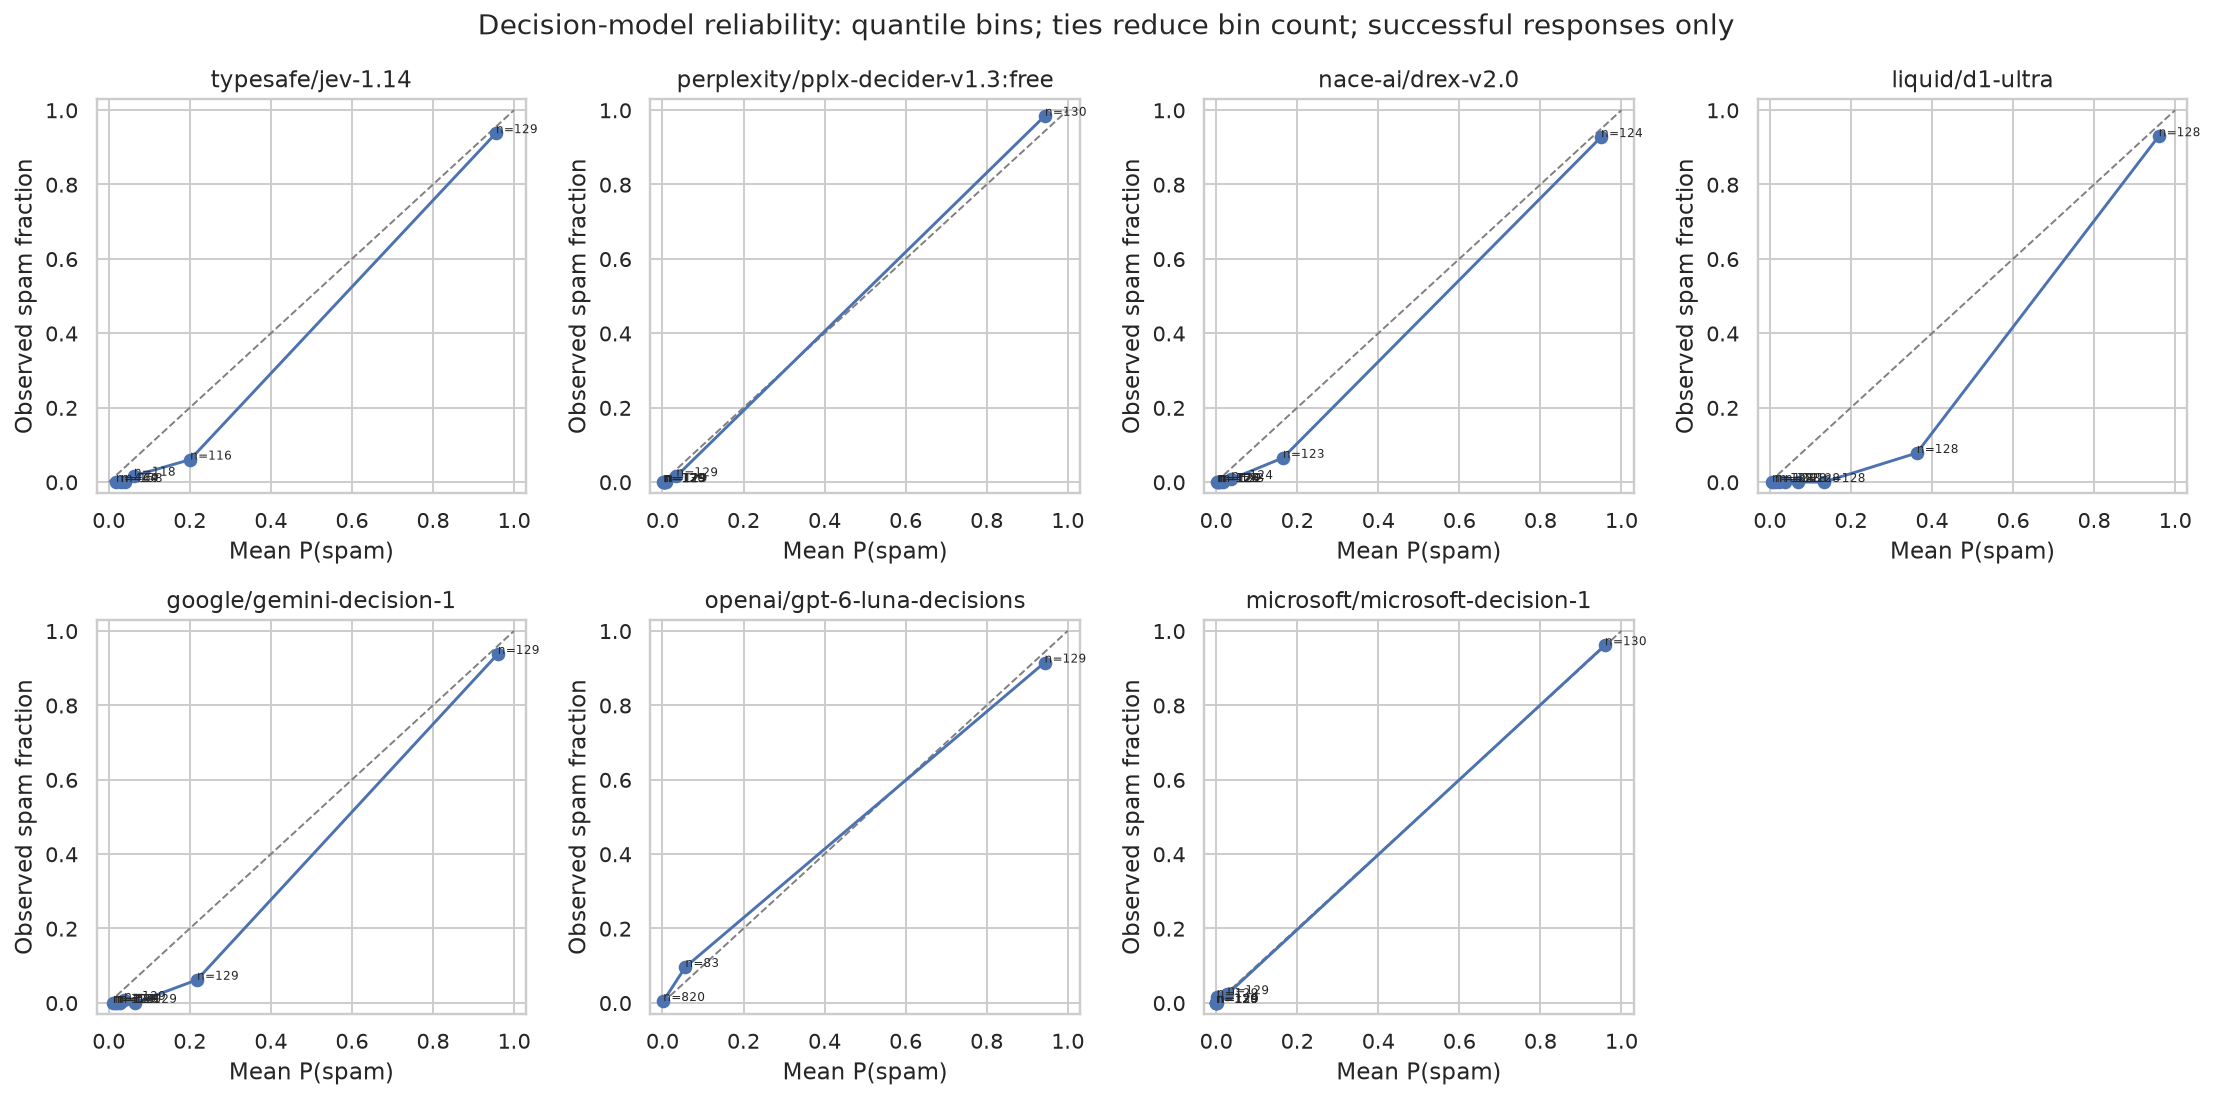

,left,right,common_successes,common_success_coverage,delta_f1_left_minus_right,ci_low,ci_high,bootstrap_repetitions,unit,note
0,ml,llm,1034,1.0,0.007905,-0.011184,0.025207,500,template family,Exploratory paired intervals; no multiple-comp...
1,ml,decision,1034,1.0,-0.023900,-0.043477,-0.005717,500,template family,Exploratory paired intervals; no multiple-comp...
2,llm,decision,1034,1.0,-0.031805,-0.051941,-0.011625,500,template family,Exploratory paired intervals; no multiple-comp...


,candidate,coverage,interval_scope,f1_ci_low,f1_ci_high,bootstrap_repetitions,unit
0,openai/gpt-6-luna,1.000000,F1 conditional on successful responses,0.913778,0.972496,500,template family
1,anthropic/claude-haiku-5.5,1.000000,F1 conditional on successful responses,0.784846,0.882070,500,template family
2,qwen/qwen3.8-flash,1.000000,F1 conditional on successful responses,0.894509,0.955513,500,template family
3,google/gemini-4-hydrogen,1.000000,F1 conditional on successful responses,0.932326,0.980078,500,template family
4,openai/gpt-6.1-sol,1.000000,F1 conditional on successful responses,0.931502,0.980705,500,template family
5,deepseek/deepseek-v4.1-flash-1017,1.000000,F1 conditional on successful responses,0.867500,0.939232,500,template family
6,meta/muse-ember,1.000000,F1 conditional on successful responses,0.918233,0.972282,500,template family
7,typesafe/jev-1.14,1.000000,F1 conditional on successful responses,0.899332,0.959089,500,template family
8,perplexity/pplx-decider-v1.3:free,1.000000,F1 conditional on successful responses,0.973793,1.000000,500,template family
9,nace-ai/drex-v2.0,0.956480,F1 conditional on successful responses,0.879597,0.951337,500,template family


,candidate,point,threshold,attempted,completed,coverage,end_to_end_accuracy,accuracy,spam_f1,macro_f1,precision,recall,false_positive_rate,tn,fp,fn,tp,ham_support,spam_support,average_precision,brier,log_loss
0,openai/gpt-6-luna,primary,NaN,1034,1034,1.000000,0.986460,0.986460,0.945736,0.969001,0.953125,0.938462,0.006637,898,6,8,122,904,130,NaN,NaN,NaN
1,anthropic/claude-haiku-5.5,primary,NaN,1034,1034,1.000000,0.952611,0.952611,0.836120,0.904211,0.739645,0.961538,0.048673,860,44,5,125,904,130,NaN,NaN,NaN
2,qwen/qwen3.8-flash,primary,NaN,1034,1034,1.000000,0.981625,0.981625,0.928302,0.958882,0.911111,0.946154,0.013274,892,12,7,123,904,130,NaN,NaN,NaN
3,google/gemini-4-hydrogen,primary,NaN,1034,1034,1.000000,0.989362,0.989362,0.956522,0.975231,0.983740,0.930769,0.002212,902,2,9,121,904,130,NaN,NaN,NaN
4,openai/gpt-6.1-sol,primary,NaN,1034,1034,1.000000,0.989362,0.989362,0.956175,0.975061,0.991736,0.923077,0.001106,903,1,10,120,904,130,NaN,NaN,NaN
5,deepseek/deepseek-v4.1-flash-1017,primary,NaN,1034,1034,1.000000,0.975822,0.975822,0.905660,0.945897,0.888889,0.923077,0.016593,889,15,10,120,904,130,NaN,NaN,NaN
6,meta/muse-ember,primary,NaN,1034,1034,1.000000,0.986460,0.986460,0.945736,0.969001,0.953125,0.938462,0.006637,898,6,8,122,904,130,NaN,NaN,NaN
7,typesafe/jev-1.14,higher_precision,0.730000,1034,1034,1.000000,0.982592,0.982592,0.928571,0.959330,0.959016,0.900000,0.005531,899,5,13,117,904,130,NaN,NaN,NaN
8,typesafe/jev-1.14,primary,0.650000,1034,1034,1.000000,0.982592,0.982592,0.930233,0.960144,0.937500,0.923077,0.008850,896,8,10,120,904,130,0.975831,0.016886,0.079306
9,perplexity/pplx-decider-v1.3:free,higher_precision,0.472326,1034,1034,1.000000,0.997099,0.997099,0.988327,0.993335,1.000000,0.976923,0.000000,904,0,3,127,904,130,NaN,NaN,NaN


In [8]:
test_results = comparison("test")
if test_results.empty:
    display(
        Markdown(
            "Final test evaluation is pending; no development results are presented as test results."
        )
    )
else:
    display(test_results.sort_values(["group", "spam_f1"], ascending=[True, False]))
figure("test_f1")
figure("test_precision")
figure("test_recall")
figure("test_accuracy")
figure("selected_local_diagnostics")
figure("hosted_confusion")
figure("decision_reliability")
if Path("reports/paired_selected_comparisons.csv").exists():
    display(pd.read_csv("reports/paired_selected_comparisons.csv"))
if Path("reports/hosted_test_uncertainty.csv").exists():
    display(pd.read_csv("reports/hosted_test_uncertainty.csv"))
if Path("reports/hosted_operating_points.csv").exists():
    display(pd.read_csv("reports/hosted_operating_points.csv"))

## Cost and quality tradeoffs

Separate development spend from final evaluation. Report cost per 1,000 attempted and successfully completed SMS, unknown charges, cache/token usage, and projected per-million cost under explicit assumptions. Include retries and failures. Unknown cost is not zero; free promotional pricing may change. Reasoning tokens can already be included in output accounting, so do not double count them.

Local compute has no provider API charge, but hardware, electricity, and hosting are not free. Without a measured infrastructure pricing model, local dollar cost is reported as unmeasured.

{'reported_usd': 5.162991676014,
 'accounted_usd': 5.274930442014,
 'unknown_attempts': 167,
 'authorized_usd': 10.0,
 'note': 'Accounted total includes retained reservations for unknown charges.'}

,stage,model,attempts,reported_usd,accounted_usd,unknown_charges,input_tokens,output_tokens,reasoning_tokens,cached_tokens
0,augmentation,openai/gpt-6-luna,472,0.071714,0.074248,1,143926.0,114643.0,0.0,0.0
1,development,anthropic/claude-haiku-5.5,192,0.011317,0.011317,0,103572.0,1920.0,0.0,0.0
2,development,deepseek/deepseek-v4.1-flash-1017,192,0.002456,0.002456,0,49347.0,1273.0,0.0,26201.0
3,development,google/gemini-4-hydrogen,192,0.246906,0.246906,0,81589.0,16603.0,11960.0,0.0
4,development,google/gemini-decision-1,192,0.003570,0.003570,0,35696.0,0.0,NaN,NaN
5,development,liquid/d1-ultra,192,0.000934,0.006108,14,22249.0,0.0,NaN,NaN
6,development,meta/muse-ember,192,0.021757,0.021757,0,50514.0,38355.0,35557.0,25744.0
7,development,microsoft/microsoft-decision-1,192,0.000947,0.000947,0,22556.0,192.0,NaN,NaN
8,development,nace-ai/drex-v2.0,192,0.001178,0.004861,7,19631.0,6775.0,NaN,NaN
9,development,openai/gpt-6-luna,192,0.006121,0.006121,0,47768.0,2688.0,0.0,0.0


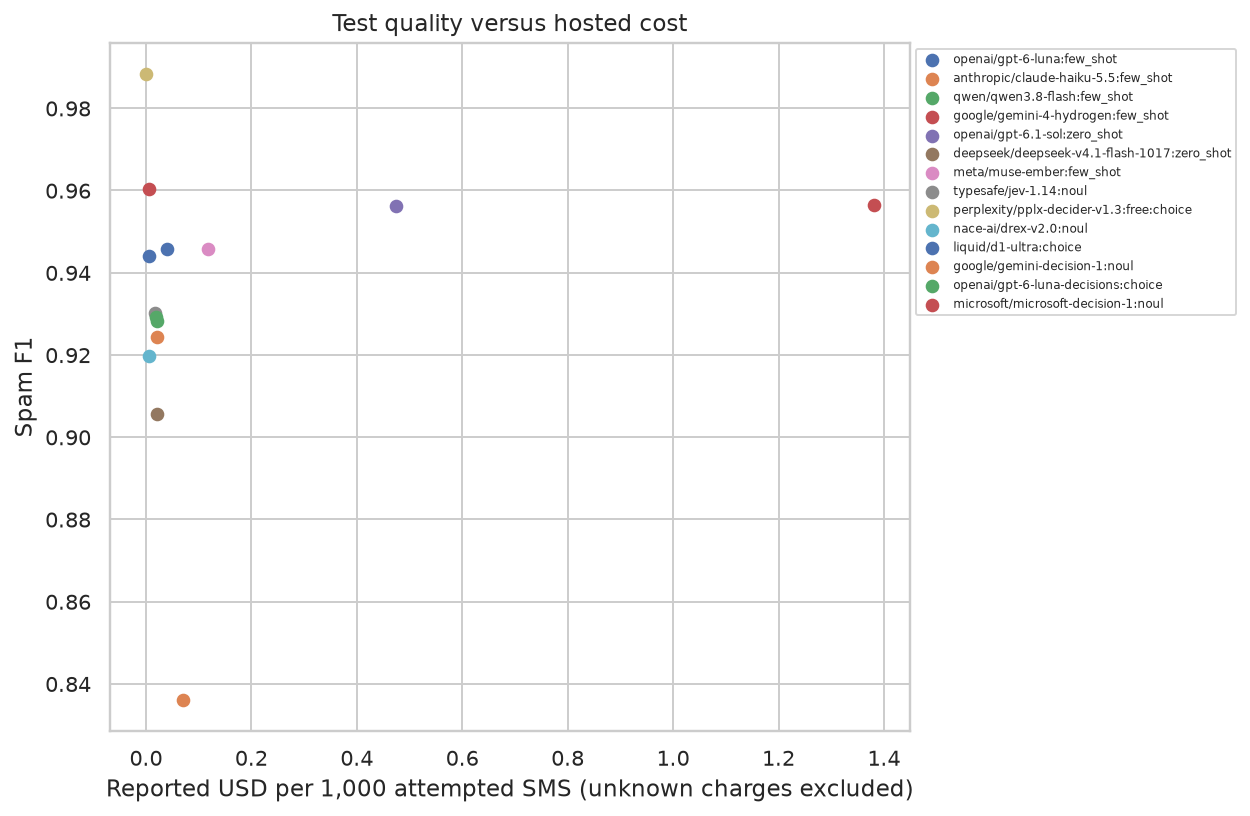

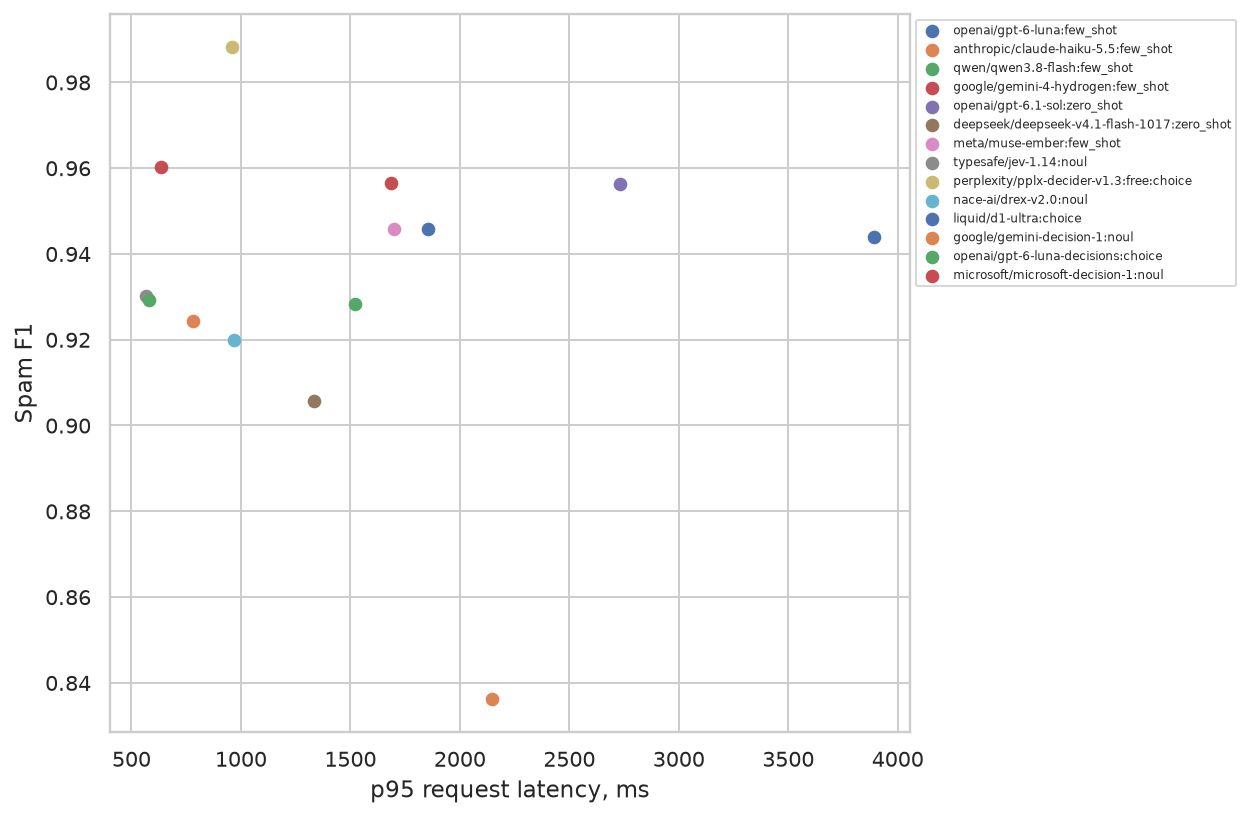

In [9]:
if Path("reports/cost_summary.json").exists():
    display(read_json("reports/cost_summary.json"))
    display(pd.read_csv("reports/cost_ledger_summary.csv"))
figure("test_cost")
figure("test_latency")

## Error analysis, selection, and deployment

Inspect errors after freezing models; this analysis must not feed further tuning on the same test set. False positives represent legitimate SMS flagged, while false negatives represent missed spam. Repeated-template, short-message, URL, digit, and capitalization slices are descriptive; small slices do not support broad claims.

Deploy one selected local ML pipeline, one selected hosted LLM, and one selected decision model. The FastAPI application runs inference only, with validated requests, explicit errors, bounded concurrency/timeouts, and budget controls. Reviewers supply their own OpenRouter key. Docker packages dependencies and the local artifact; hosted inference still requires internet access.

Some misses can reflect conversational-looking spam or jokes labelled spam in the source corpus. Keep the supplied labels unchanged, discuss ambiguous examples, and avoid relabelling test errors to improve reported scores.

Future monitoring needs representative labelled traffic, error/latency/cost signals, version tracking, challenger evaluation, and rollback. Distribution drift alone does not prove accuracy loss.

In [10]:
if Path("configs/local_selection.json").exists():
    display(read_json("configs/local_selection.json"))
if Path("configs/hosted_frozen.json").exists():
    frozen = read_json("configs/hosted_frozen.json")
    display(
        pd.DataFrame(
            [
                {
                    "group": group,
                    "model": cfg["model"],
                    "variant": cfg["variant"],
                    "threshold": cfg.get("threshold"),
                    "selection_stage": frozen["selection_stage"],
                }
                for group, cfg in frozen["champions"].items()
            ]
        )
    )
if Path("reports/local_test_errors.csv").exists():
    errors = pd.read_csv("reports/local_test_errors.csv")
    display(errors.head(20))
    display(
        Markdown(
            f"Local champion errors: {len(errors)}. Full examples saved in reports/local_test_errors.csv."
        )
    )
if Path("reports/error_slices.csv").exists():
    slices = pd.read_csv("reports/error_slices.csv")
    selected = read_json("configs/local_selection.json")["candidate"]
    if (slices.candidate == selected + "__original").any():
        selected += "__original"
    display(slices[slices.candidate == selected])
    display(
        Markdown(
            "Slices are descriptive, overlap, and can have very few spam examples. Do not interpret no-spam-slice F1 as a useful quality estimate."
        )
    )

{'candidate': 'logistic_char',
 'kind': 'classical',
 'artifact': 'artifacts/release/model.joblib',
 'sha256': '3c2f3ded80b47df84bbe3d380304aa1a8c67ddaefcc5b2226013028cba6d53e3',
 'selection_basis': 'validation spam F1, then precision; frozen before test evaluation'}

,group,model,variant,threshold,selection_stage
0,llm,google/gemini-4-hydrogen,few_shot,NaN,validation
1,decision,perplexity/pplx-decider-v1.3:free,choice,0.472326,validation


,id,group,target,prediction,score,text
0,a3f481aad9e9bb54fd4b0a4a62f26f9671b77369ddef8d...,144c7008f436dff42577717dc66dd3cfc342ef5accb036...,1,0,0.005689,"Did you hear about the new ""Divorce Barbie""? I..."
1,8e703377ff2b26a37ef80144697062d7a41173655e3ab9...,3776e15be9cc5aeca4ae9521216dfdd6c5efd2a09ce09a...,0,1,0.398462,Yun ah.the ubi one say if ü wan call by tomorr...
2,9464220223197b8d0cdcc43c610ef71a85cd01e1849a2e...,9ed1b2584530cc7c860dbbc529782586af49d4c7137fd6...,1,0,0.043873,For sale - arsenal dartboard. Good condition b...
3,71997053d94a78b56facf3eecd6411185b3582bcd1ddf5...,d82c2d69a19d9611b71b221e1ddee4203d1b8f13ae3091...,1,0,0.100723,Hi ya babe x u 4goten bout me?' scammers getti...
4,f20ff85f534bfd8b068ec319aa206e2c93dec3727aca94...,f03bd6ee30acc4ab7ea9c6db6391721a55debc5eaf3d36...,1,0,0.149443,RCT' THNQ Adrian for U text. Rgds Vatian
5,661f37920f40dd1143524296eaa73424d93ad71b59b719...,4917a1d345b09fd6750f4744a9bf1198fccf1c1dcdfbb4...,1,0,0.021854,TBS/PERSOLVO. been chasing us since Sept for£3...
6,b9b6b0c59809c3214ee9c08548d83b518c9ce357c304ee...,763d2dd3fdc315f8724438921334d2d07b9297ef4594a0...,1,0,0.052378,Money i have won wining number 946 wot do i do...
7,c39b8db5d68c0bb2d44ad500d464ca9ee5e0b7bf7db16d...,e3d0b667825d91c16f093e4c925a0f9b41cbc9d022644f...,1,0,0.205460,"Hi babe its Chloe, how r u? I was smashed on s..."
8,2a7bcfd0de9367026cf53a4c0dd96b36a6c89bf0ae8f83...,89bdad5470a413c73202a87f8c6576f29619e19cd230f3...,1,0,0.119004,"Latest News! Police station toilet stolen, cop..."


Local champion errors: 9. Full examples saved in reports/local_test_errors.csv.

,candidate,slice,attempted_spam,failed_spam,failed_ham,attempted,completed,coverage,end_to_end_accuracy,accuracy,spam_f1,macro_f1,precision,recall,false_positive_rate,tn,fp,fn,tp,ham_support,spam_support
78,logistic_char__original,all,130,0,0,1034,1034,1.0,0.991296,0.991296,0.964427,0.979734,0.991870,0.938462,0.001106,903,1,8,122,904,130
79,logistic_char__original,short_le_40_chars,3,0,0,334,334,1.0,0.997006,0.997006,0.800000,0.899246,1.000000,0.666667,0.000000,331,0,1,2,331,3
80,logistic_char__original,long_gt_160_chars,11,0,0,48,48,1.0,0.979167,0.979167,0.952381,0.969524,1.000000,0.909091,0.000000,37,0,1,10,37,11
81,logistic_char__original,contains_url,16,0,0,16,16,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0,0,0,16,0,16
82,logistic_char__original,contains_digit,124,0,0,267,267,1.0,0.981273,0.981273,0.979592,0.981145,0.991736,0.967742,0.006993,142,1,4,120,143,124
83,logistic_char__original,digit_fraction_gt_10pct,76,0,0,82,82,1.0,0.987805,0.987805,0.993464,0.951277,0.987013,1.000000,0.166667,5,1,0,76,6,76


Slices are descriptive, overlap, and can have very few spam examples. Do not interpret no-spam-slice F1 as a useful quality estimate.

## Reproduction and limitations

Use the repository [README](../README.md) for installation, training, hosted-budget, report, and deployment commands. The [experiment protocol](../docs/ml_experiments.md) defines data boundaries, search budgets and evaluation scope; the [architecture](../docs/architecture.md) explains the shared components. The [implementation status](../reports/implementation_status.md) records what actually ran, limitations, and verification evidence.

Results are specific to the recorded split, dataset, code/configuration hashes, hardware, provider routing, and execution date. This small historical public corpus cannot establish modern production performance or exclude pretrained contamination. Hosted inference can change behind stable names. Training family grouping is conservative and may miss paraphrases. Calibration and high-precision estimates have limited sample support.

The repository contains saved results so reading this notebook need not spend credits. Regenerating hosted experiments requires an explicit budget and key.